# Multi-Modal Medical Data Analysis Tutorial

**Audience:** Medical science students  
**Goal:** Learn how to work with medical data from multiple sources (modalities) using Python

---

## Background

In clinical practice, patient information is often collected from different sources:

- **Modality A — Patient Demographics:** Basic characteristics like age, sex, and body mass index (BMI)
- **Modality B — Clinical Measurements:** Vital signs and laboratory results including blood pressure, heart rate, oxygen saturation, HbA1c, triglycerides, and HDL cholesterol
- **Modality C — Genotypes:** Genetic risk variants associated with type 2 diabetes, encoded as **dosage values** (0, 1, or 2 copies of the risk allele)

In this tutorial, we will generate a synthetic (simulated) dataset of **100 patients** and assign each patient one of three health labels:

| Label | Definition |
|-------|-----------|
| **Healthy** | Normal glucose metabolism |
| **Pre-diabetes** | Impaired fasting glucose / impaired glucose tolerance |
| **Diabetes** | Established type 2 diabetes mellitus |

> **Note:** The diagnosis labels are based on HbA1c thresholds from clinical guidelines:
> - Healthy: HbA1c < 39 mmol/mol
> - Pre-diabetes: HbA1c 39–47 mmol/mol
> - Diabetes: HbA1c > 47 mmol/mol

---

### About Modality B — Clinical Measurements

Modality B captures seven laboratory and vital-sign measurements per patient. Two of these — **triglycerides** and **HDL cholesterol** — are strongly correlated with metabolic health status and are included here as key discriminators between healthy, pre-diabetic, and diabetic patients:

| Measurement | Healthy | Pre-diabetes | T2D |
|-------------|---------|-------------|-----|
| Triglycerides | < 2.0 mmol/L | ~1.5 – 2.5 mmol/L | ~2.0 – 4.0+ mmol/L |
| HDL (Men) | > 1.0 mmol/L | ~0.9 – 1.1 mmol/L | < 1.0 mmol/L |
| HDL (Women) | > 1.3 mmol/L | ~1.1 – 1.3 mmol/L | < 1.3 mmol/L |

Elevated triglycerides and reduced HDL cholesterol are hallmarks of **insulin resistance** and the **metabolic syndrome** — conditions that precede and accompany type 2 diabetes. They are part of the standard lipid panel ordered in routine diabetes screening.

---

### About Modality C — Genotypes

**Single nucleotide polymorphisms (SNPs)** are the most common type of genetic variation in the human genome — a single "letter" in the DNA sequence that differs between individuals. The ten SNPs in this dataset are well-studied variants associated with type 2 diabetes risk in large genome-wide association studies (GWAS):

| SNP | Gene region | Notes |
|-----|-------------|-------|
| rs7903146 | *TCF7L2* | Strongest known T2D risk variant |
| rs12255372 | *TCF7L2* | |
| rs9939609 | *FTO* | Also linked to obesity |
| rs1801282 | *PPARG* | Affects insulin sensitivity |
| rs13266634 | *SLC30A8* | Zinc transporter in β-cells |
| rs7754840 | *CDKAL1* | |
| rs10811661 | *CDKN2A/B* | Cell-cycle regulator |
| rs5219 | *KCNJ11* | Potassium channel in β-cells |
| rs2237892 | *KCNQ1* | |
| rs4402960 | *IGF2BP2* | |

Each SNP is encoded as a **dosage** — the number of copies of the risk allele a person carries:

| Value | Meaning |
|-------|---------|
| **0** | No risk alleles (homozygous reference) |
| **1** | One risk allele (heterozygous) |
| **2** | Two risk alleles (homozygous risk) |

> **Important:** Although these SNPs are statistically associated with T2D risk at the population level, they do **not** directly determine whether any individual has diabetes. In this tutorial, the genotypes are generated **independently of the diagnosis label** — they are pure noise for predicting who is healthy, pre-diabetic, or diabetic.  
>
> However, genetic variation *does* influence how patients respond to medication. Later in this notebook, we will use Modality C to model differential drug responses in diabetic patients — a real-world application of pharmacogenomics.

---

## How to use this notebook

---

## Step 1: Generate Synthetic Patient Data

We will create three tables of 100 patients:
- **Modality A** — demographics (age, sex, BMI)
- **Modality B** — clinical measurements (blood pressure, heart rate, SpO₂, HbA1c)
- **Modality C** — genotypes: dosage values (0 / 1 / 2) for 10 T2D-associated SNPs

Each patient gets a **diagnosis label** derived from their HbA1c value.

### Step 1.1 — Load the required libraries

Python uses **libraries** (pre-built toolkits) to handle data. Run the cell below to load them.  
You do not need to change anything here.

In [ ]:
import numpy as np       # For numerical operations and random number generation
import pandas as pd      # For creating and managing data tables

### Step 1.2 — Set the parameters

> **You can change the values in this cell.**
>
> - `RANDOM_SEED` — any whole number. Changing it gives you a different set of patients, but the same seed always gives the same result (reproducibility).
> - `N_PATIENTS` — how many patients to generate.
> - The three `PROP_` values control how many patients fall into each diagnosis group. They **must add up to 1.0**.

In [ ]:
# ── PARAMETERS (feel free to change these) ────────────────────────────────────

RANDOM_SEED  = 42    # Any whole number — ensures the same data every time you run

N_PATIENTS   = 200  # Total number of patients to simulate

# Proportion of patients in each diagnosis group (must sum to 1.0)
PROP_HEALTHY      = 0.60   # 60 % healthy
PROP_PREDIABETES  = 0.25   # 25 % pre-diabetes
PROP_DIABETES     = 0.15   # 15 % diabetes

# ─────────────────────────────────────────────────────────────────────────────
# Quick check: proportions must sum to 1
assert abs(PROP_HEALTHY + PROP_PREDIABETES + PROP_DIABETES - 1.0) < 1e-9, \
    "ERROR: The three proportions must sum to exactly 1.0"

print("Settings confirmed:")
print(f"  Random seed  : {RANDOM_SEED}")
print(f"  Patients     : {N_PATIENTS}")
print(f"  Healthy      : {int(PROP_HEALTHY * N_PATIENTS)} patients ({PROP_HEALTHY*100:.0f}%)")
print(f"  Pre-diabetes : {int(PROP_PREDIABETES * N_PATIENTS)} patients ({PROP_PREDIABETES*100:.0f}%)")
print(f"  Diabetes     : {int(PROP_DIABETES * N_PATIENTS)} patients ({PROP_DIABETES*100:.0f}%)")

Settings confirmed:
  Random seed  : 42
  Patients     : 200
  Healthy      : 120 patients (60%)
  Pre-diabetes : 50 patients (25%)
  Diabetes     : 30 patients (15%)


### Step 1.3 — Generate the patient data

The cell below creates both modality tables. The data is **simulated but clinically realistic** — feature values are generated within ranges that vary by diagnosis group, reflecting real-world correlations (e.g., higher BMI and HbA1c in diabetic patients).

> You do not need to change anything here — just run the cell.

In [ ]:
np.random.seed(RANDOM_SEED)

# ── 1. Patient names ──────────────────────────────────────────────────────────
first_names = [
    "Alice", "Bob", "Carol", "David", "Emma", "Frank", "Grace", "Henry",
    "Isla", "James", "Karen", "Liam", "Mia", "Noah", "Olivia", "Peter",
    "Quinn", "Rachel", "Sam", "Tara", "Uma", "Victor", "Wendy", "Xander",
    "Yara", "Zoe", "Aaron", "Beth", "Chris", "Diana", "Evan", "Fiona",
    "George", "Hannah", "Ivan", "Julia", "Kevin", "Laura", "Mike", "Nina",
    "Oscar", "Paula", "Quentin", "Rose", "Steve", "Teresa", "Umar", "Vera",
    "Will", "Xena"
]
last_names = [
    "Smith", "Johnson", "Williams", "Brown", "Jones", "Garcia", "Miller",
    "Davis", "Wilson", "Taylor", "Anderson", "Thomas", "Jackson", "White",
    "Harris", "Martin", "Thompson", "Young", "Lee", "Walker", "Hall",
    "Allen", "King", "Wright", "Scott", "Green", "Baker", "Adams", "Nelson",
    "Hill", "Ramirez", "Campbell", "Mitchell", "Roberts", "Carter", "Evans",
    "Turner", "Phillips", "Parker", "Edwards", "Collins", "Stewart", "Morris",
    "Rogers", "Reed", "Cook", "Morgan", "Bell", "Murphy", "Bailey"
]

# Sample unique full names
first = np.random.choice(first_names, size=N_PATIENTS, replace=True)
last  = np.random.choice(last_names,  size=N_PATIENTS, replace=True)
names = [f"{f} {l}" for f, l in zip(first, last)]

# ── 2. Assign diagnosis labels ────────────────────────────────────────────────
labels = np.random.choice(
    ["Healthy", "Pre-diabetes", "Diabetes"],
    size=N_PATIENTS,
    p=[PROP_HEALTHY, PROP_PREDIABETES, PROP_DIABETES]
)

# ── 3. Generate HbA1c (mmol/mol) — drives the label ──────────────────────────
# Healthy: 20–38  |  Pre-diabetes: 39–47  |  Diabetes: 48–80
hba1c = np.array([
    np.random.randint(20, 39)  if lbl == "Healthy"      else
    np.random.randint(39, 48)  if lbl == "Pre-diabetes"  else
    np.random.randint(48, 81)
    for lbl in labels
])

# ── 4. Modality A features ────────────────────────────────────────────────────
# Age (years): slightly older in diabetes groups
age = np.array([
    np.random.randint(20, 66) if lbl == "Healthy"      else
    np.random.randint(30, 71) if lbl == "Pre-diabetes" else
    np.random.randint(35, 76)
    for lbl in labels
])

# Sex
sex = np.random.choice(["Male", "Female"], size=N_PATIENTS)

# BMI (kg/m²): higher in diabetes groups
bmi = np.array([
    round(np.random.uniform(18.5, 27.0), 1) if lbl == "Healthy"      else
    round(np.random.uniform(21, 27.0), 1) if lbl == "Pre-diabetes" else
    round(np.random.uniform(27.0, 40.0), 1)
    for lbl in labels
])

# ── 5. Modality B features ────────────────────────────────────────────────────
# Blood pressure: systolic 120–139 mmHg, diastolic 80–89 mmHg (two separate columns)
systolic  = np.random.randint(120, 140, size=N_PATIENTS)
diastolic = np.random.randint(80,  90,  size=N_PATIENTS)

# Heart rate (bpm): 60–90
heart_rate = np.random.randint(71, 91, size=N_PATIENTS)

# Oxygen saturation (%): 95.0–100.0
spo2 = np.round(np.random.uniform(96.5, 100.0, size=N_PATIENTS), 1)

# Triglycerides (mmol/L): progressively higher with metabolic deterioration
# Healthy: < 2.0  |  Pre-diabetes: ~1.5–2.5  |  T2D: ~2.0–4.5
triglycerides = np.array([
    round(np.random.uniform(0.5, 1.9), 2) if lbl == "Healthy"      else
    round(np.random.uniform(1.4, 2.6), 2) if lbl == "Pre-diabetes" else
    round(np.random.uniform(2.0, 4.5), 2)
    for lbl in labels
])

# HDL cholesterol (mmol/L): progressively lower with metabolic deterioration
# Thresholds are sex-dependent (Men: >1.0 normal; Women: >1.3 normal)
hdl = np.array([
    round(np.random.uniform(1.0, 1.9), 2) if (lbl == "Healthy"      and s == "Male")   else
    round(np.random.uniform(1.3, 2.1), 2) if (lbl == "Healthy"      and s == "Female") else
    round(np.random.uniform(0.9, 1.2), 2) if (lbl == "Pre-diabetes" and s == "Male")   else
    round(np.random.uniform(1.1, 1.4), 2) if (lbl == "Pre-diabetes" and s == "Female") else
    round(np.random.uniform(0.6, 1.0), 2) if (lbl == "Diabetes"     and s == "Male")   else
    round(np.random.uniform(0.7, 1.2), 2)                                                # Diabetes, Female
    for lbl, s in zip(labels, sex)
])

# ── 6. Assemble Modality A and B DataFrames ───────────────────────────────────
modality_A = pd.DataFrame({
    "Name"    : names,
    "Age"     : age,
    "Sex"     : sex,
    "BMI"     : bmi,
    "Label"   : labels,
})

modality_B = pd.DataFrame({
    "Name"                      : names,
    "Systolic BP (mmHg)"        : systolic,
    "Diastolic BP (mmHg)"       : diastolic,
    "Heart Rate (bpm)"          : heart_rate,
    "SpO2 (%)"                  : spo2,
    "HbA1c (mmol/mol)"          : hba1c,
    "Triglycerides (mmol/L)"    : triglycerides,
    "HDL Cholesterol (mmol/L)"  : hdl,
    "Label"                     : labels,
})

# ── 7. Modality C — Genotypes ─────────────────────────────────────────────────
# Ten T2D-associated SNPs encoded as dosage (0 / 1 / 2 copies of the risk allele).
# Generated INDEPENDENTLY of the diagnosis label — genotypes are noise for diagnosis.
# Minor allele frequencies (MAF) are drawn from realistic ranges per SNP.

t2d_risk_snps = [
    "rs7903146",   # TCF7L2   — strongest T2D GWAS hit
    "rs12255372",  # TCF7L2
    "rs9939609",   # FTO      — also linked to obesity
    "rs1801282",   # PPARG    — insulin sensitivity
    "rs13266634",  # SLC30A8  — β-cell zinc transporter
    "rs7754840",   # CDKAL1
    "rs10811661",  # CDKN2A/B — cell-cycle regulator
    "rs5219",      # KCNJ11   — β-cell potassium channel
    "rs2237892",   # KCNQ1
    "rs4402960",   # IGF2BP2
]

# Use a separate RNG seeded independently so genotypes do not interfere
# with the rest of the simulation
rng_geno = np.random.default_rng(RANDOM_SEED + 99)

# Realistic minor allele frequencies (approximately matching published values)
mafs = [0.30, 0.28, 0.43, 0.12, 0.32, 0.38, 0.18, 0.35, 0.40, 0.30]

snp_data = {}
for snp, maf in zip(t2d_risk_snps, mafs):
    p0 = (1 - maf) ** 2          # homozygous reference
    p1 = 2 * maf * (1 - maf)     # heterozygous
    p2 = maf ** 2                 # homozygous risk
    snp_data[snp] = rng_geno.choice([0, 1, 2], size=N_PATIENTS, p=[p0, p1, p2])

modality_C = pd.DataFrame(snp_data)
modality_C["Label"] = labels
modality_C.insert(0, "Name", names)

print("✓ Data generated successfully!")
print(f"\nModality A shape : {modality_A.shape[0]} rows × {modality_A.shape[1]} columns")
print(f"Modality B shape : {modality_B.shape[0]} rows × {modality_B.shape[1]} columns")
print(f"Modality C shape : {modality_C.shape[0]} rows × {modality_C.shape[1]} columns")
print(f"\nLabel distribution:\n{modality_A['Label'].value_counts().to_string()}")
print(f"\nModality B columns: {list(modality_B.columns)}")

✓ Data generated successfully!

Modality A shape : 200 rows × 5 columns
Modality B shape : 200 rows × 9 columns
Modality C shape : 200 rows × 12 columns

Label distribution:
Label
Healthy         121
Pre-diabetes     50
Diabetes         29

Modality B columns: ['Name', 'Systolic BP (mmHg)', 'Diastolic BP (mmHg)', 'Heart Rate (bpm)', 'SpO2 (%)', 'HbA1c (mmol/mol)', 'Triglycerides (mmol/L)', 'HDL Cholesterol (mmol/L)', 'Label']


### Step 1.4 — Preview the data

Run the cells below to see the first few rows of each modality table.

In [ ]:
print("=== Modality A — Demographics (first 10 patients) ===")
modality_A.head(10)

=== Modality A — Demographics (first 10 patients) ===


,Name,Age,Sex,BMI,Label
0,Mike Harris,39,Male,21.6,Pre-diabetes
1,Chris Campbell,22,Female,20.6,Healthy
2,Olivia Campbell,60,Female,24.6,Healthy
3,Quentin Wright,64,Male,25.8,Healthy
4,Henry Collins,37,Female,25.6,Healthy
5,Uma Murphy,65,Female,23.4,Pre-diabetes
6,Mike Murphy,41,Male,24.2,Healthy
7,Sam Thomas,53,Female,20.2,Healthy
8,Wendy Parker,37,Female,22.8,Pre-diabetes
9,Karen Johnson,59,Female,26.1,Healthy


In [ ]:
print("=== Modality B — Clinical Measurements (first 10 patients) ===")
modality_B.head(10)

=== Modality B — Clinical Measurements (first 10 patients) ===


,Name,Systolic BP (mmHg),Diastolic BP (mmHg),Heart Rate (bpm),SpO2 (%),HbA1c (mmol/mol),Triglycerides (mmol/L),HDL Cholesterol (mmol/L),Label
0,Mike Harris,139,84,87,97.3,39,2.41,1.02,Pre-diabetes
1,Chris Campbell,123,87,82,99.2,25,0.64,1.97,Healthy
2,Olivia Campbell,127,89,85,97.5,25,1.18,1.61,Healthy
3,Quentin Wright,139,82,85,99.4,31,0.71,1.51,Healthy
4,Henry Collins,138,83,76,98.0,32,0.95,1.77,Healthy
5,Uma Murphy,132,88,82,98.8,43,2.28,1.16,Pre-diabetes
6,Mike Murphy,133,86,90,96.8,35,1.17,1.33,Healthy
7,Sam Thomas,129,80,88,98.7,30,1.03,1.57,Healthy
8,Wendy Parker,130,83,84,98.1,43,1.87,1.11,Pre-diabetes
9,Karen Johnson,121,83,72,98.6,23,1.14,1.32,Healthy


In [ ]:
print("=== Modality C — Genotypes (first 10 patients) ===")
modality_C.head(10)

=== Modality C — Genotypes (first 10 patients) ===


,Name,rs7903146,rs12255372,rs9939609,rs1801282,rs13266634,rs7754840,rs10811661,rs5219,rs2237892,rs4402960,Label
0,Mike Harris,1,0,1,0,1,1,1,2,1,1,Pre-diabetes
1,Chris Campbell,2,0,2,0,0,0,1,1,1,0,Healthy
2,Olivia Campbell,0,0,2,0,1,1,0,0,2,0,Healthy
3,Quentin Wright,0,0,1,0,0,1,0,1,1,0,Healthy
4,Henry Collins,1,1,0,0,1,0,0,0,0,1,Healthy
5,Uma Murphy,1,0,1,1,2,0,1,1,2,0,Pre-diabetes
6,Mike Murphy,0,0,1,0,1,1,2,0,1,1,Healthy
7,Sam Thomas,0,0,1,0,1,0,0,0,1,0,Healthy
8,Wendy Parker,1,1,2,0,0,1,0,2,2,0,Pre-diabetes
9,Karen Johnson,1,0,1,0,1,2,0,1,2,1,Healthy


---

> **What you should see:**
> - All three tables have **100 rows** (one per patient) and share the same **Name** column — this is how the modalities are linked.
> - In Modality A and B, HbA1c values align with the label, and BMI tends to be higher in the *Diabetes* group.
> - In Modality C, each column is a SNP with values 0, 1, or 2. Notice that the dosage values appear **random across all three diagnosis groups** — this is by design. These genotypes were generated independently of the label and carry no information about who has diabetes.
>
> In the next steps, we will explore, visualise, and analyse all three modalities.

---

## Step 2: Principal Component Analysis (PCA)

### What is PCA?

Each patient in our dataset is described by several measurements (age, BMI, HbA1c, etc.). Visualising many variables at once is impossible on a flat screen.

**PCA** is a mathematical technique that compresses all those variables into just **2 "summary" axes** (called principal components, PC1 and PC2) while keeping as much of the original information as possible. Think of it as projecting a 3-D object onto a 2-D shadow — you lose some detail but you can now see the overall shape.

We will run PCA **separately on each modality** and colour every dot by the patient's diagnosis label. If the groups form visible clusters, it means the features in that modality carry useful diagnostic information.

### Step 2.1 — Load additional libraries

Run the cell below to load the tools needed for PCA and plotting.

In [ ]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

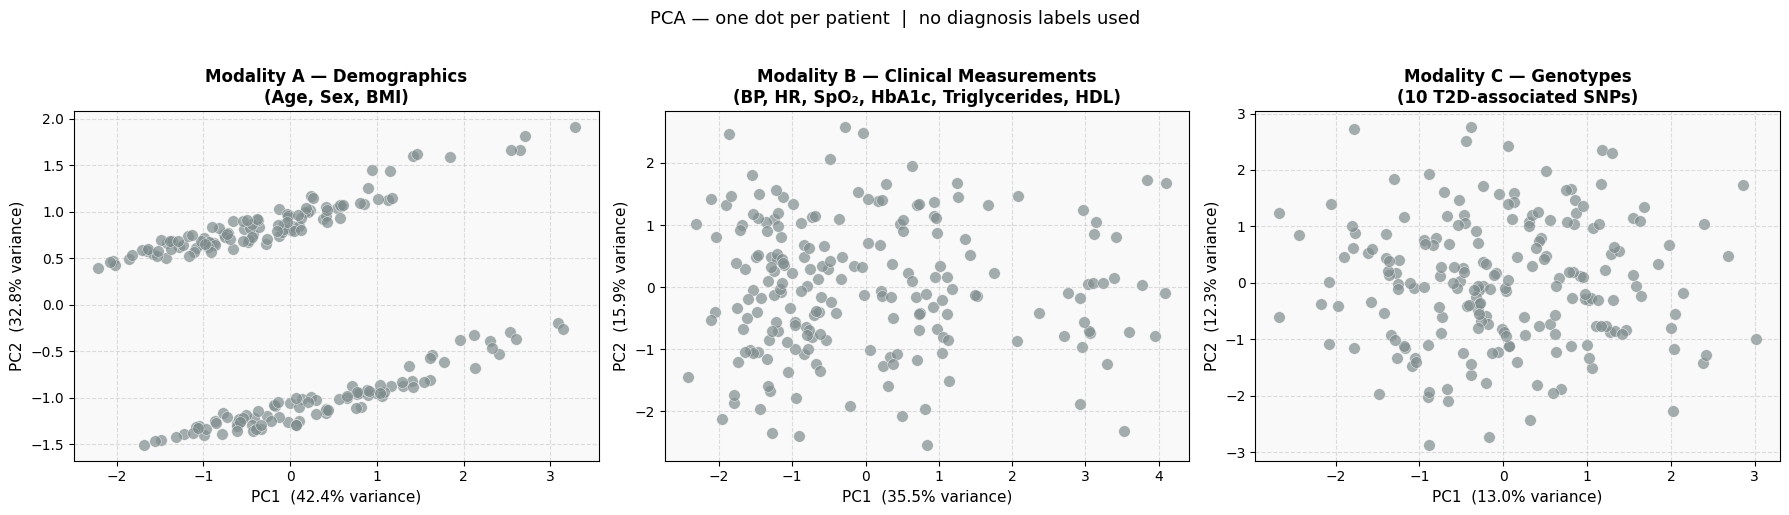

In [ ]:
# ── Colour palette and label order (defined here, reused throughout) ──────────
label_colors = {
    "Healthy"      : "#2ecc71",   # green
    "Pre-diabetes" : "#f39c12",   # orange
    "Diabetes"     : "#e74c3c",   # red
}
label_order = ["Healthy", "Pre-diabetes", "Diabetes"]

# ── Helper: fit PCA and return coordinates + fitted objects for later use ──────
def run_pca(feature_matrix):
    scaler = StandardScaler()
    scaled = scaler.fit_transform(feature_matrix)
    pca    = PCA(n_components=2, random_state=RANDOM_SEED)
    coords = pca.fit_transform(scaled)
    var_explained = pca.explained_variance_ratio_ * 100
    return coords, var_explained, scaler, pca

# ── Prepare feature matrices ───────────────────────────────────────────────────
sex_encoded = LabelEncoder().fit_transform(modality_A["Sex"])

features_A = np.column_stack([
    modality_A["Age"].values,
    sex_encoded,
    modality_A["BMI"].values,
])

features_B = modality_B[[
    "Systolic BP (mmHg)",
    "Diastolic BP (mmHg)",
    "Heart Rate (bpm)",
    "SpO2 (%)",
    "HbA1c (mmol/mol)",
    "Triglycerides (mmol/L)",
    "HDL Cholesterol (mmol/L)",
]].values

features_C = modality_C.drop(columns=["Name", "Label"]).values

# ── Run PCA ────────────────────────────────────────────────────────────────────
pca_A, var_A, scaler_A, pca_obj_A = run_pca(features_A)
pca_B, var_B, scaler_B, pca_obj_B = run_pca(features_B)
pca_C, var_C, scaler_C, pca_obj_C = run_pca(features_C)

# ── Plot — unlabeled (all patients the same colour) ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], pca_A, var_A, "Modality A — Demographics\n(Age, Sex, BMI)"),
    (axes[1], pca_B, var_B, "Modality B — Clinical Measurements\n(BP, HR, SpO₂, HbA1c, Triglycerides, HDL)"),
    (axes[2], pca_C, var_C, "Modality C — Genotypes\n(10 T2D-associated SNPs)"),
]

for ax, coords, var, title in panels:
    ax.scatter(
        coords[:, 0], coords[:, 1],
        c="#7f8c8d", alpha=0.70, edgecolors="white", linewidths=0.4, s=70,
    )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% variance)", fontsize=11)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% variance)", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

fig.suptitle(
    "PCA — one dot per patient  |  no diagnosis labels used",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

### Reveal the labels

Look at the plots above. In **Modality B** you can probably see two or three distinct clouds of dots — even without any colour. That structure was discovered entirely from the raw numbers, with no knowledge of who has diabetes.

This is the key idea behind **unsupervised learning**: an algorithm finds patterns in data without being told what to look for. PCA is one of the simplest examples.

Now run the cell below to colour each dot by the patient's actual diagnosis label. How well does the structure you spotted match the clinical categories?

### Step 2.2 — Run PCA and plot

Before running PCA we need to do two things:

1. **Encode Sex** — computers cannot do maths with the words "Male" / "Female", so we convert them to 0 / 1.
2. **Standardise the features** — variables measured on very different scales (e.g. age 20–75 vs SpO₂ 95–100) would otherwise dominate the PCA. Standardisation puts every variable on the same scale (mean = 0, standard deviation = 1).

We will first run PCA and plot the result **without using any diagnosis labels** — every patient appears as an identical grey dot. PCA only sees the raw numbers; it has no idea who is healthy, pre-diabetic, or diabetic. Yet structure may emerge from the data on its own.

> You do not need to change anything — just run the cell.

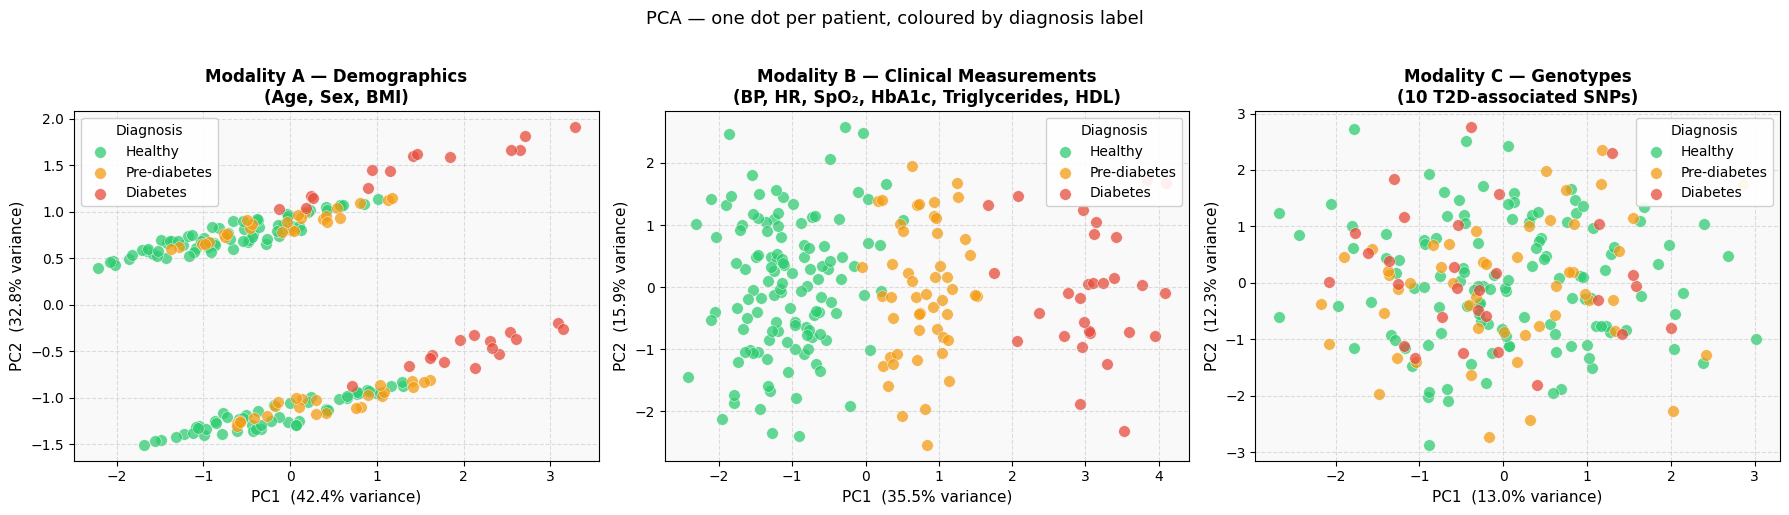

In [ ]:
# ── Plot — labelled by diagnosis ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], pca_A, var_A, "Modality A — Demographics\n(Age, Sex, BMI)"),
    (axes[1], pca_B, var_B, "Modality B — Clinical Measurements\n(BP, HR, SpO₂, HbA1c, Triglycerides, HDL)"),
    (axes[2], pca_C, var_C, "Modality C — Genotypes\n(10 T2D-associated SNPs)"),
]

for ax, coords, var, title in panels:
    for lbl in label_order:
        mask = modality_A["Label"] == lbl
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            c=label_colors[lbl], label=lbl,
            alpha=0.75, edgecolors="white", linewidths=0.4, s=70,
        )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% variance)", fontsize=11)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% variance)", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(title="Diagnosis", framealpha=0.9)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

fig.suptitle(
    "PCA — one dot per patient, coloured by diagnosis label",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

### What to look for in the plots

| Observation | Interpretation |
|-------------|---------------|
| Groups form **separate clusters** | The features in that modality clearly distinguish the diagnosis groups |
| Groups **overlap heavily** | The modality alone is not very discriminative |
| **Modality B clusters best** | Expected — HbA1c directly defines the label, and triglycerides/HDL reinforce the separation |
| **Modality A shows partial clustering** | Age and BMI are associated with diabetes risk, but are not definitive |
| **Modality C shows no clustering** | By design — genotypes were generated independently of diagnosis. The three groups are completely mixed, confirming that these SNPs carry no information about who has diabetes |
| **% variance on axis labels** | How much information PC1 / PC2 capture; higher % = less information lost by the compression |

> **Clinical note:** The strong separation in Modality B is driven by multiple correlated metabolic markers — HbA1c (the diagnostic criterion), **triglycerides** (elevated in insulin resistance), and **HDL cholesterol** (reduced in metabolic syndrome). Together these three features create a powerful multivariate signal that PCA can detect without any label information. The weaker (but still visible) separation in Modality A reflects the real-world association between higher BMI / older age and diabetes risk. The complete absence of separation in Modality C is a key lesson: a modality that is noise for one task (diagnosis) can still be invaluable for another task (predicting drug response), as we will see later in this notebook.

### Step 2.3 — What drives each principal component?

A PCA scatter plot tells us *where* patients sit, but not *why*. To answer the "why", we look at two complementary visualisations:

1. **Loadings bar chart** — the contribution of each original feature to PC1 and PC2 (population-level summary)
2. **Contribution heatmap** — the same loadings multiplied by each individual's standardised feature value, showing exactly how each person's PC score is assembled from their measurements

We wrap both plots into a single helper function and apply it to **Modality A** and **Modality B** in turn.

> You do not need to change anything — just run the cells.

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.gridspec as gridspec

def plot_pca_analysis(features, feature_names, pca_coords, pca_obj, scaler,
                      var, diagnosis_labels, title):
    """
    Two plots for one modality (PC1 only):
      1. Loadings bar chart  — which features drive PC1
      2. Contribution heatmap — per-feature PC1 contributions for every individual
    """
    n_features = len(feature_names)
    n_patients = features.shape[0]
    loadings   = pca_obj.components_          # (2, n_features)

    # ── Plot 1: PC1 Loadings bar chart ────────────────────────────────────────
    x = np.arange(n_features)
    fig, ax = plt.subplots(1, 1, figsize=(max(9, n_features * 1.6), 4))

    bars = ax.bar(x, loadings[0], width=0.6, color="#3498db", alpha=0.8,
                  edgecolor="white", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(feature_names, fontsize=10, rotation=30, ha="right")
    ax.set_ylabel("Loading (contribution)", fontsize=11)
    ax.set_title(f"PC1  ({var[0]:.1f}% variance)", fontsize=11, fontweight="bold")
    ax.set_ylim(-1, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

    for bar, val in zip(bars, loadings[0]):
        if val >= 0:
            if val > 0.85:
                y_pos, va = val - 0.06, "top"
            else:
                y_pos, va = val + 0.04, "bottom"
        else:
            if val < -0.85:
                y_pos, va = val + 0.06, "bottom"
            else:
                y_pos, va = val - 0.06, "top"

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            y_pos, f"{val:+.2f}",
            ha="center", va=va, fontsize=9, fontweight="bold",
        )

    fig.suptitle(f"PCA Loadings — {title}", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

    # ── Plot 2: PC1 Contribution heatmap ──────────────────────────────────────
    X_scaled      = scaler.transform(features)
    sort_idx      = np.argsort(pca_coords[:, 0])
    X_sorted      = X_scaled[sort_idx]
    labels_sorted = np.asarray(diagnosis_labels)[sort_idx]

    pc1_contrib = loadings[0, :, np.newaxis] * X_sorted.T   # (n_features, N)
    heat        = pc1_contrib

    lbl_int = {"Healthy": 0, "Pre-diabetes": 1, "Diabetes": 2}
    strip   = np.array([lbl_int[l] for l in labels_sorted])[np.newaxis, :]

    fig = plt.figure(figsize=(16, 2.5 + n_features * 0.6))
    gs  = gridspec.GridSpec(
        2, 2,
        height_ratios=[0.12, 1], width_ratios=[1, 0.03],
        hspace=0.04, wspace=0.02,
    )
    ax_strip  = fig.add_subplot(gs[0, 0])
    ax_heat   = fig.add_subplot(gs[1, 0])
    ax_cbar   = fig.add_subplot(gs[1, 1])
    ax_spacer = fig.add_subplot(gs[0, 1])
    ax_spacer.set_visible(False)

    diag_cmap = ListedColormap(["#2ecc71", "#f39c12", "#e74c3c"])
    ax_strip.pcolormesh(strip, cmap=diag_cmap, vmin=-0.5, vmax=2.5)
    ax_strip.set_xlim(0, n_patients)
    ax_strip.set_ylim(0, 1)
    ax_strip.set_yticks([0.5])
    ax_strip.set_yticklabels(["Diagnosis"], fontsize=9)
    ax_strip.set_xticks([])
    ax_strip.set_title(
        f"{title} — per-feature contributions to PC1 score",
        fontsize=11, fontweight="bold", pad=6, loc="left",
    )
    ax_strip.legend(
        handles=[
            mpatches.Patch(color="#2ecc71", label="Healthy"),
            mpatches.Patch(color="#f39c12", label="Pre-diabetes"),
            mpatches.Patch(color="#e74c3c", label="Diabetes"),
        ],
        loc="upper right",
        bbox_to_anchor=(1.0, 1.45),
        bbox_transform=ax_strip.transAxes,
        fontsize=8, framealpha=0.9, ncol=3, borderaxespad=0,
    )

    vmax = np.abs(heat).max()
    im   = ax_heat.pcolormesh(heat, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax_heat.set_xlim(0, n_patients)
    ax_heat.set_ylim(n_features, 0)

    row_labels = [f"PC1  ←  {n}" for n in feature_names]
    ax_heat.set_yticks([r + 0.5 for r in range(n_features)])
    ax_heat.set_yticklabels(row_labels, fontsize=9)

    ax_heat.text(
        n_patients + 2, n_features / 2, "PC1",
        fontsize=10, fontweight="bold",
        va="center", ha="left", color="#2980b9", clip_on=False,
    )

    ax_heat.set_xlabel(
        "Individuals  (leftmost: lowest PC1 score  ·  rightmost: highest PC1 score)",
        fontsize=10,
    )

    cb = plt.colorbar(im, cax=ax_cbar)
    cb.set_label("Contribution to PC1 score (loading × standardised value)", fontsize=9)

    plt.tight_layout()
    plt.show()

**How to read the loadings bar chart**

Each bar answers: *"If a patient moves in the positive direction along this PC axis, which features are responsible?"*  
A large bar = that feature strongly shapes the axis. A bar near zero = that feature barely contributes.

**How to read the contribution heatmap**

- Reading **across a row** (one feature, all patients): you see how that feature varies across individuals — red cells push toward higher PC scores, blue toward lower.
- Reading **down a column** (one patient): the cells in the PC1 section sum to that patient's exact PC1 score, making the score fully decomposable.
- The **diagnosis strip** at the top reveals whether the PC1 gradient aligns with clinical categories.

#### Modality A — Demographics (Age, Sex, BMI)

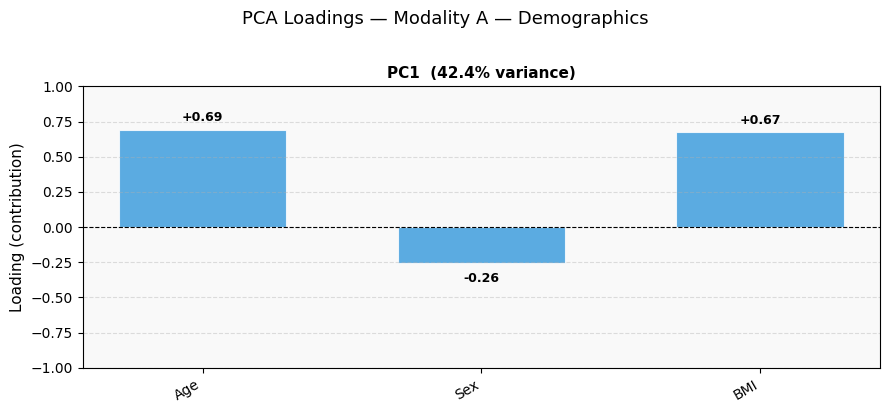

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/1381103655.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


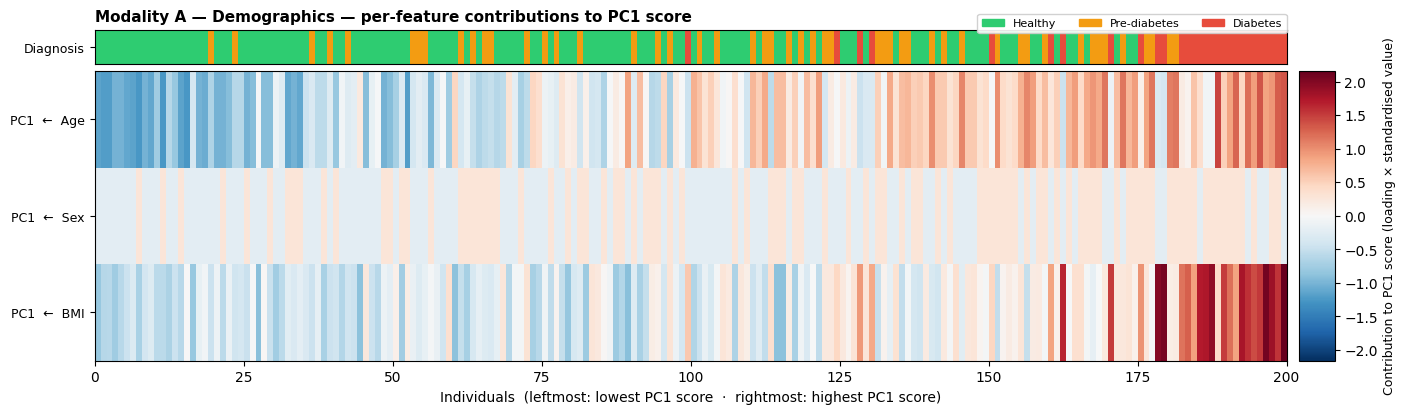

In [ ]:
plot_pca_analysis(
    features       = features_A,
    feature_names  = ["Age", "Sex", "BMI"],
    pca_coords     = pca_A,
    pca_obj        = pca_obj_A,
    scaler         = scaler_A,
    var            = var_A,
    diagnosis_labels = modality_A["Label"].values,
    title          = "Modality A — Demographics",
)

#### Modality B — Clinical Measurements (BP, HR, SpO₂, HbA1c, Triglycerides, HDL)

Modality B now includes **seven features**. Three of these — HbA1c, triglycerides, and HDL cholesterol — are strongly associated with health status and should load heavily onto the first principal component.

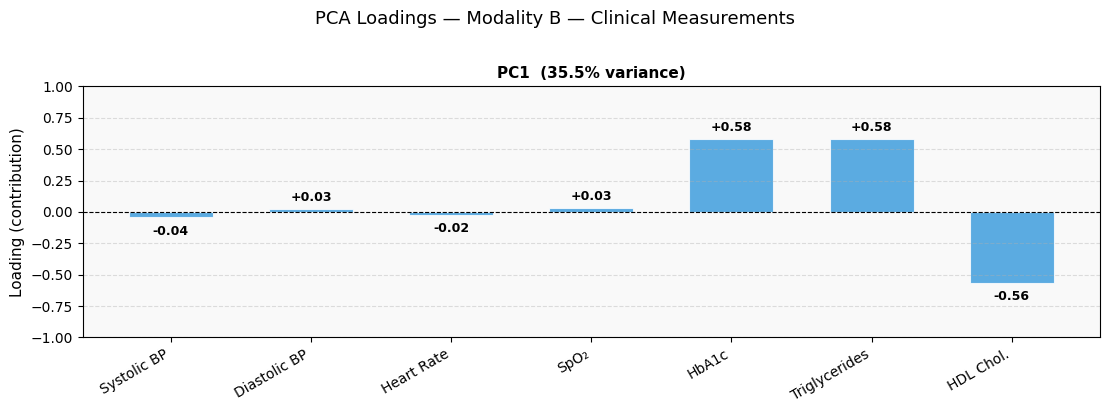

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/1381103655.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


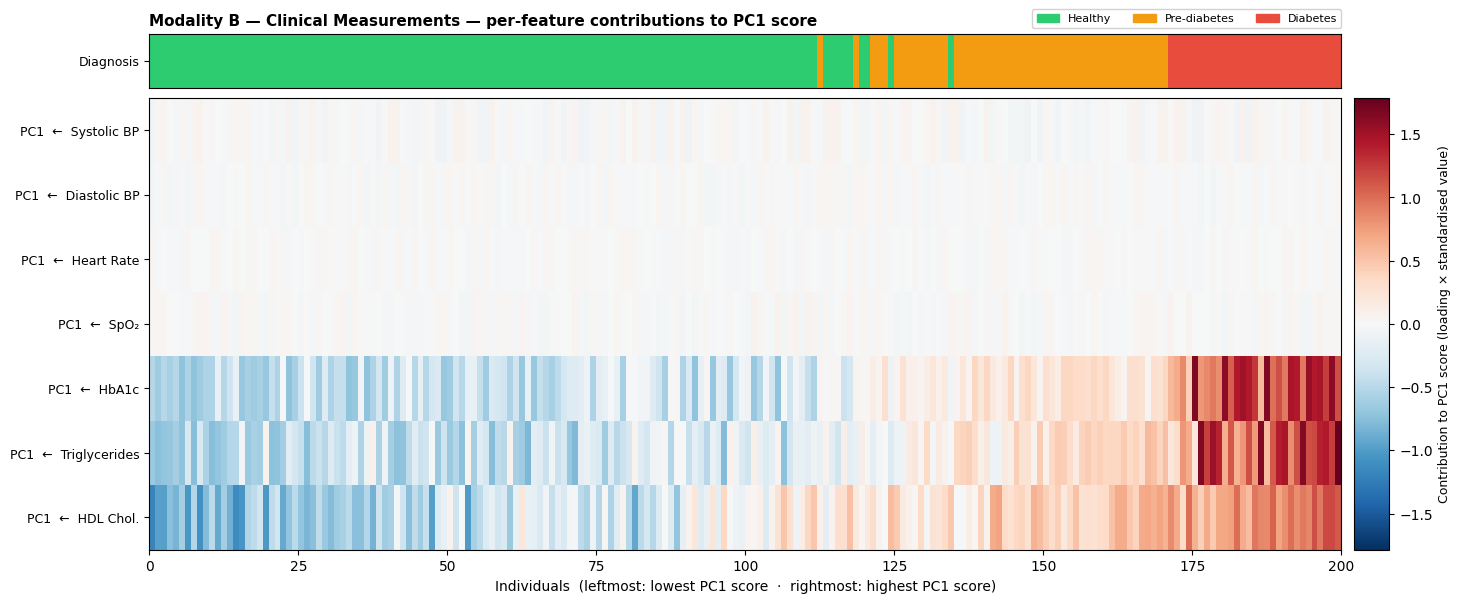

In [ ]:
plot_pca_analysis(
    features       = features_B,
    feature_names  = ["Systolic BP", "Diastolic BP", "Heart Rate", "SpO₂", "HbA1c",
                      "Triglycerides", "HDL Chol."],
    pca_coords     = pca_B,
    pca_obj        = pca_obj_B,
    scaler         = scaler_B,
    var            = var_B,
    diagnosis_labels = modality_B["Label"].values,
    title          = "Modality B — Clinical Measurements",
)

#### Modality C — SNP Genotypes (10 T2D-associated variants)

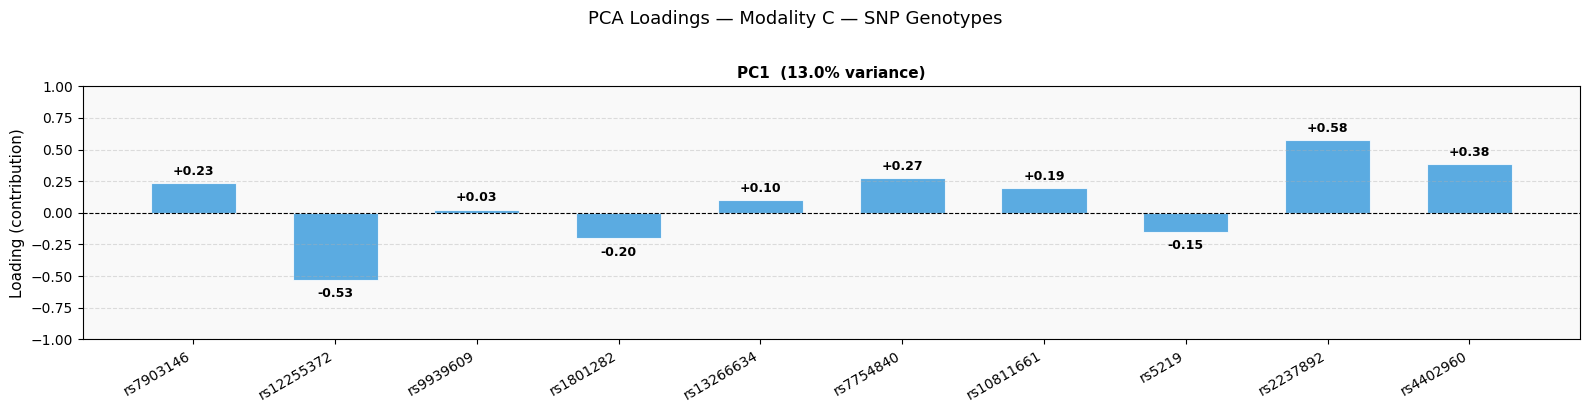

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/1381103655.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


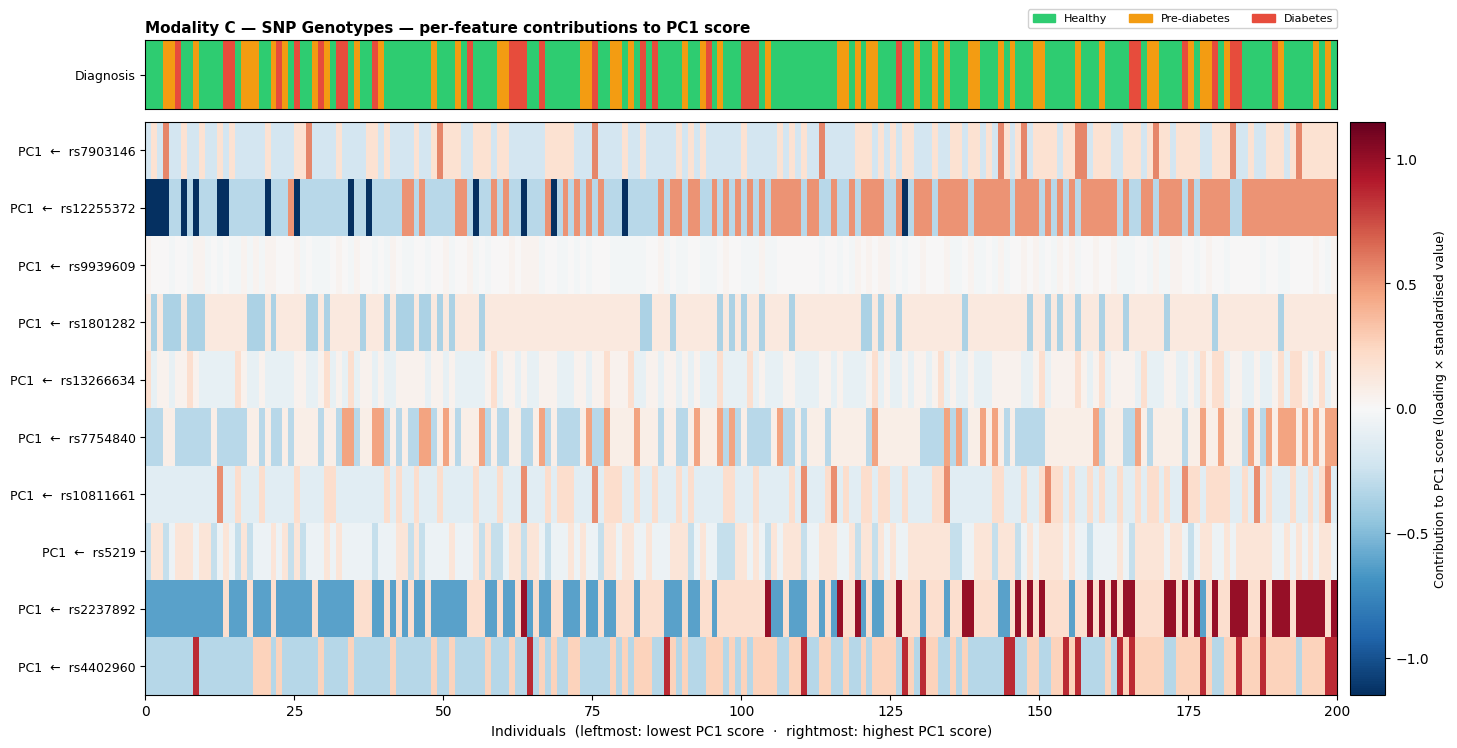

In [ ]:
plot_pca_analysis(
    features       = features_C,
    feature_names  = [
        "rs7903146", "rs12255372", "rs9939609", "rs1801282", "rs13266634",
        "rs7754840", "rs10811661", "rs5219", "rs2237892", "rs4402960",
    ],
    pca_coords     = pca_C,
    pca_obj        = pca_obj_C,
    scaler         = scaler_C,
    var            = var_C,
    diagnosis_labels = modality_C["Label"].values,
    title          = "Modality C — SNP Genotypes",
)

---

## Step 3: Multimodal Analysis — Combining Modalities

### What does "multimodal" mean?

In medicine, a **modality** is a source of patient information:
- A blood test is one modality
- A clinical examination is another
- An imaging scan is yet another
- A genetic profile is yet another

When we analyse each modality **separately** (as in Step 2), we only see part of the picture. **Multimodal analysis** means merging information from multiple sources into a single representation before making a decision.

### How do we combine modalities?

The simplest approach is **feature concatenation**: place the columns from two or more modalities side by side into one wider table, then run PCA on that combined table.

We will compare **six combinations** arranged in a 2 × 3 grid:

|  | Without genotypes | With genotypes (+ C) |
|--|-------------------|----------------------|
| **Demographics only (A)** | A only | A + C |
| **Clinical only (B)** | B only | B + C |
| **Both clinical (A + B)** | A + B | A + B + C |

Reading down each column shows what the clinical features reveal about diagnosis.  
Reading across each row shows what the genotypes **add** (or fail to add) to the same combination.

> Because genotypes were generated independently of the diagnosis label, adding Modality C should not improve the diagnostic separation — confirming that Modality C is noise for this task. We will see a very different picture when we use genotypes to predict drug response later in the notebook.

> You do not need to change anything — just run the cell.

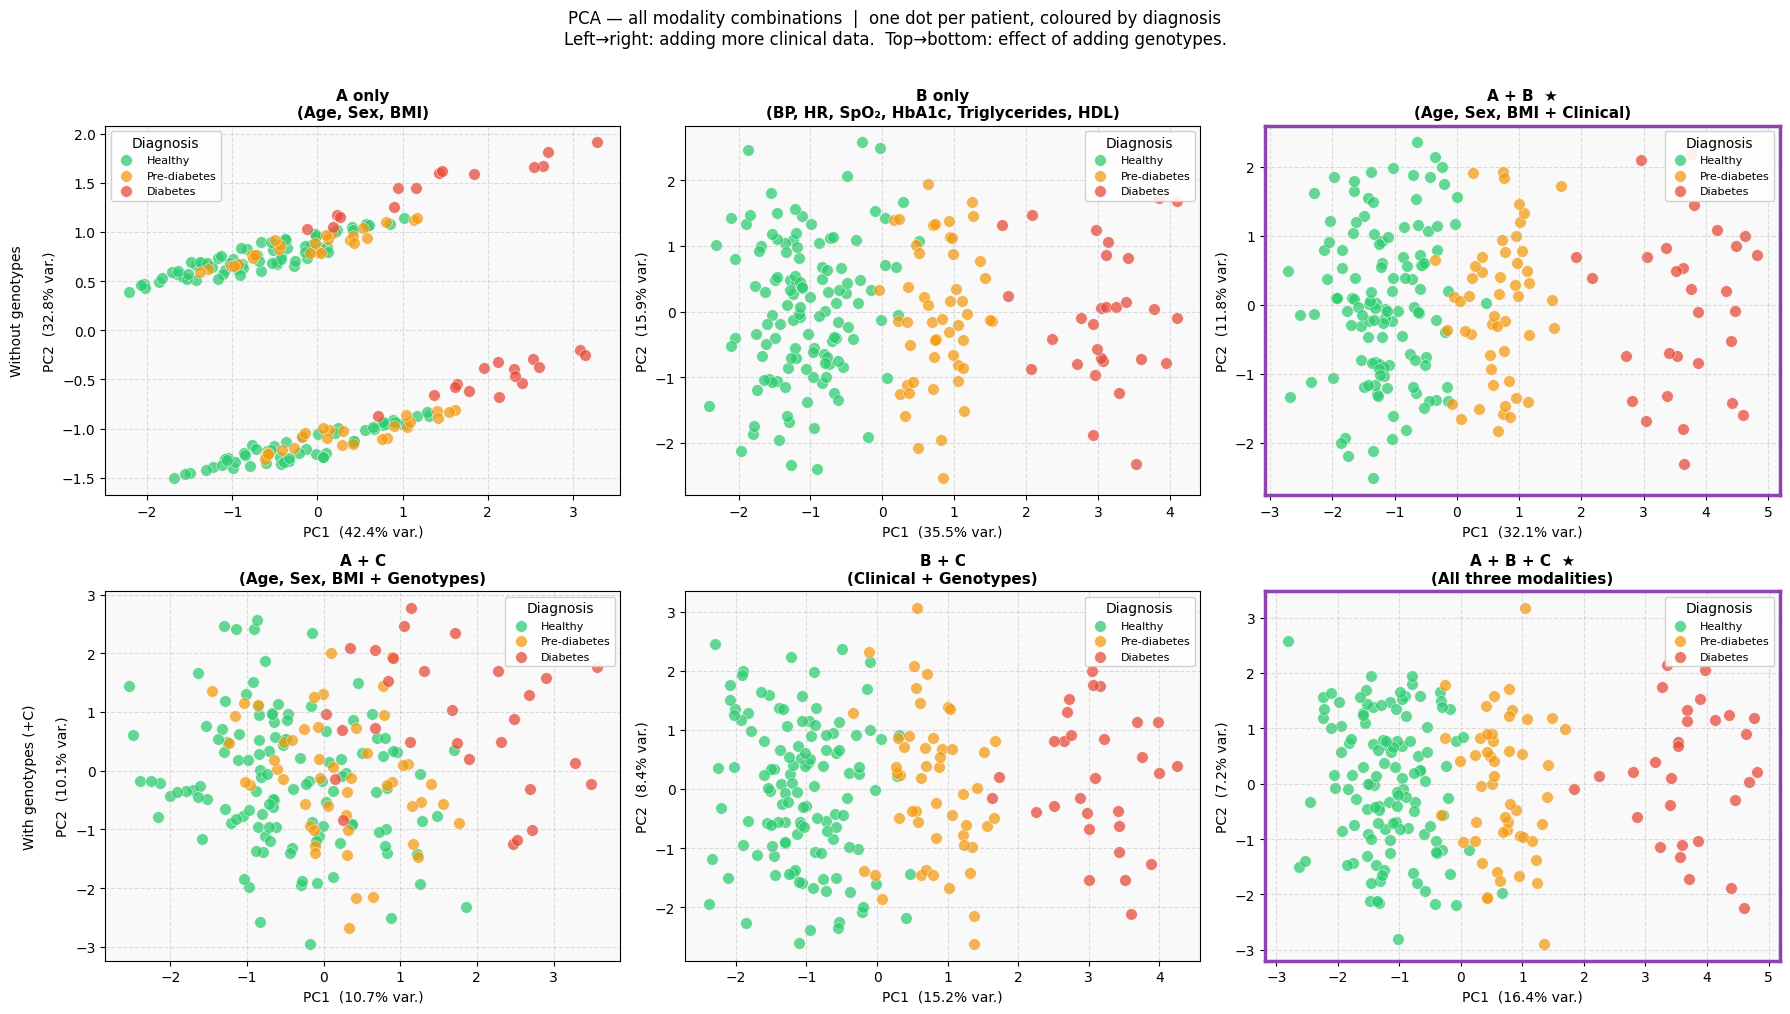

Variance captured by PC1 + PC2:
  A only   : 75.2%
  B only   : 51.5%
  A + B    : 43.9%
  A + C    : 20.8%
  B + C    : 23.5%
  A + B + C : 23.6%


In [ ]:
# ── Build all combined feature matrices ───────────────────────────────────────
# features_A, features_B, features_C were prepared in Step 2
features_AB  = np.hstack([features_A, features_B])
features_AC  = np.hstack([features_A, features_C])
features_BC  = np.hstack([features_B, features_C])
features_ABC = np.hstack([features_A, features_B, features_C])

# ── Run PCA on each combined matrix ───────────────────────────────────────────
pca_AB,  var_AB,  scaler_AB,  pca_obj_AB  = run_pca(features_AB)
pca_AC,  var_AC,  scaler_AC,  pca_obj_AC  = run_pca(features_AC)
pca_BC,  var_BC,  scaler_BC,  pca_obj_BC  = run_pca(features_BC)
pca_ABC, var_ABC, scaler_ABC, pca_obj_ABC = run_pca(features_ABC)

# Keep the old "combined" references pointing to A+B for backwards compatibility
pca_combined    = pca_AB
var_combined    = var_AB
scaler_combined = scaler_AB
pca_obj_combined = pca_obj_AB

# ── 2 × 3 comparison grid ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

panels = [
    # Row 0 — without genotypes
    (axes[0, 0], pca_A,   var_A,   "A only\n(Age, Sex, BMI)",                                    False),
    (axes[0, 1], pca_B,   var_B,   "B only\n(BP, HR, SpO₂, HbA1c, Triglycerides, HDL)",         False),
    (axes[0, 2], pca_AB,  var_AB,  "A + B  ★\n(Age, Sex, BMI + Clinical)",                        True),
    # Row 1 — with genotypes
    (axes[1, 0], pca_AC,  var_AC,  "A + C\n(Age, Sex, BMI + Genotypes)",                          False),
    (axes[1, 1], pca_BC,  var_BC,  "B + C\n(Clinical + Genotypes)",                              False),
    (axes[1, 2], pca_ABC, var_ABC, "A + B + C  ★\n(All three modalities)",                       True),
]

for ax, coords, var, title, highlight in panels:
    for lbl in label_order:
        mask = modality_A["Label"] == lbl
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            c=label_colors[lbl], label=lbl,
            alpha=0.75, edgecolors="white", linewidths=0.4, s=70,
        )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% var.)", fontsize=10)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% var.)", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(title="Diagnosis", framealpha=0.9, fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")
    if highlight:
        for spine in ax.spines.values():
            spine.set_edgecolor("#8e44ad")
            spine.set_linewidth(2.5)

# Row labels
axes[0, 0].set_ylabel("Without genotypes\n\n" + axes[0, 0].get_ylabel(), fontsize=10)
axes[1, 0].set_ylabel("With genotypes (+C)\n\n" + axes[1, 0].get_ylabel(), fontsize=10)

fig.suptitle(
    "PCA — all modality combinations  |  one dot per patient, coloured by diagnosis\n"
    "Left→right: adding more clinical data.  Top→bottom: effect of adding genotypes.",
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.show()

# ── Variance summary ───────────────────────────────────────────────────────────
print("Variance captured by PC1 + PC2:")
for label, var in [
    ("A only  ", var_A),
    ("B only  ", var_B),
    ("A + B   ", var_AB),
    ("A + C   ", var_AC),
    ("B + C   ", var_BC),
    ("A + B + C", var_ABC),
]:
    print(f"  {label} : {var[0]+var[1]:.1f}%")

### How to read this comparison

The grid is organised so you can make two kinds of comparison:

**Reading left → right (within a row):** Does adding more clinical information improve diagnostic separation?  
**Reading top → bottom (within a column):** Does adding genotypes (Modality C) change anything?

| Panel | What you should see | Why |
|-------|--------------------|----|
| **A only** | Partial separation — groups overlap | Age and BMI are risk factors but not diagnostic criteria |
| **B only** | Very clean separation | HbA1c directly defines the label |
| **A + B ★** | Clean separation + richer spread | Demographics add context on top of the lab result |
| **A + C** | Similar to A only — no improvement | Genotypes do not carry diagnostic information |
| **B + C** | Similar to B only — no improvement | The HbA1c signal dominates; adding SNPs dilutes rather than sharpens it |
| **A + B + C ★** | Similar to A + B — no improvement | All three modalities combined: the clustering is driven entirely by A + B; C contributes nothing to diagnosis |

The **% variance** numbers show how much information is retained after compressing all features down to 2 axes. Notice that adding Modality C increases the total feature count to 18, which tends to *lower* the % variance captured by just two components — another sign that the extra genotype dimensions are uncorrelated noise for this task.

> **Key take-away:** Modality C is deliberately non-informative for diagnosis. Comparing the top and bottom rows makes this concrete: the scatter plots look nearly identical regardless of whether genotypes are included. This illustrates an important principle in multimodal medicine — *not all modalities are relevant to every clinical question*. The right modalities depend on the task. Genotypes will prove their value when we switch from diagnosis to drug-response prediction.

---

### Step 3.2 — Does the model generalise? A validation set

So far we have been looking at the **same 100 patients** that were used to build the PCA axes. But in real clinical practice, the value of a model lies in how well it works on **patients it has never seen before**.

#### Training set vs. validation set

| Set | Patients | Role |
|-----|----------|------|
| **Training set** | 200 patients (Steps 1–3) | Used to *build* the PCA axes |
| **Validation set** | 30 new patients (this step) | Used to *test* whether the axes generalise |

The critical rule: **the PCA is not refitted**. We take the axes learned from the 200 training patients and simply ask "where do these 30 new patients land?" This is called **out-of-sample projection** — the same operation we will use for individual patients (Maria) in Step 4.

If the validation patients land in the same clusters as the training patients with matching labels, the model has genuinely learned a meaningful structure — not just memorised the training data.

> You do not need to change anything — just run the cell.

Validation set: 30 patients
Label distribution:
Healthy         16
Pre-diabetes     8
Diabetes         6


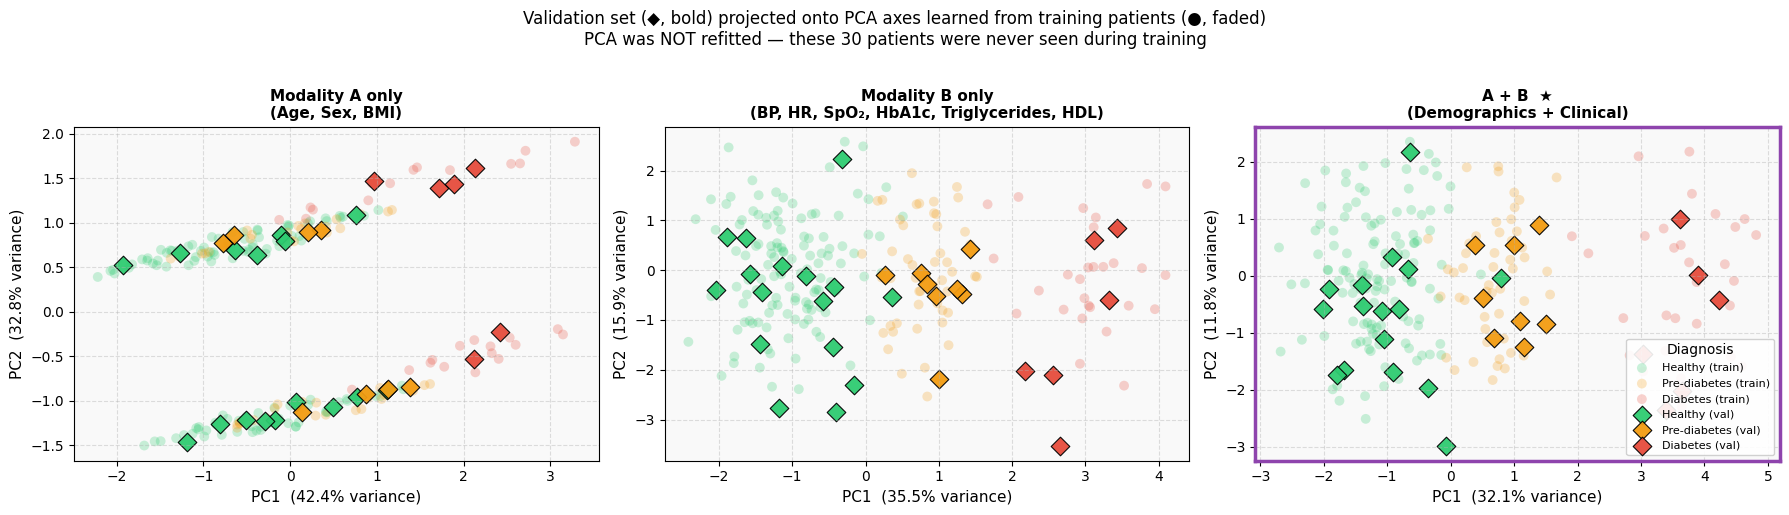

In [ ]:
N_VAL = 30
VAL_SEED = RANDOM_SEED + 7   # different seed → genuinely unseen patients
np.random.seed(VAL_SEED)

# ── Labels (same proportions as training set) ──────────────────────────────────
val_labels = np.random.choice(
    ["Healthy", "Pre-diabetes", "Diabetes"],
    size=N_VAL,
    p=[PROP_HEALTHY, PROP_PREDIABETES, PROP_DIABETES],
)

# ── HbA1c ─────────────────────────────────────────────────────────────────────
val_hba1c = np.array([
    np.random.randint(20, 39) if lbl == "Healthy"      else
    np.random.randint(39, 48) if lbl == "Pre-diabetes" else
    np.random.randint(48, 81)
    for lbl in val_labels
])

# ── Modality A features ───────────────────────────────────────────────────────
val_age = np.array([
    np.random.randint(20, 66) if lbl == "Healthy"      else
    np.random.randint(30, 71) if lbl == "Pre-diabetes" else
    np.random.randint(35, 76)
    for lbl in val_labels
])
val_sex     = np.random.choice([0, 1], size=N_VAL)   # 0 = Female, 1 = Male
val_bmi     = np.array([
    round(np.random.uniform(18.5, 27.0), 1) if lbl == "Healthy"      else
    round(np.random.uniform(21.0, 27.0), 1) if lbl == "Pre-diabetes" else
    round(np.random.uniform(27.0, 40.0), 1)
    for lbl in val_labels
])

# ── Modality B features ───────────────────────────────────────────────────────
val_systolic  = np.random.randint(120, 140, size=N_VAL)
val_diastolic = np.random.randint(80,  90,  size=N_VAL)
val_hr        = np.random.randint(60,  91,  size=N_VAL)
val_spo2      = np.round(np.random.uniform(95.0, 100.0, size=N_VAL), 1)

val_triglycerides = np.array([
    round(np.random.uniform(0.5, 1.9), 2) if lbl == "Healthy"      else
    round(np.random.uniform(1.4, 2.6), 2) if lbl == "Pre-diabetes" else
    round(np.random.uniform(2.0, 4.5), 2)
    for lbl in val_labels
])

val_hdl = np.array([
    round(np.random.uniform(1.0, 1.9), 2) if (lbl == "Healthy"      and s == 1) else  # Male
    round(np.random.uniform(1.3, 2.1), 2) if (lbl == "Healthy"      and s == 0) else  # Female
    round(np.random.uniform(0.9, 1.2), 2) if (lbl == "Pre-diabetes" and s == 1) else  # Male
    round(np.random.uniform(1.1, 1.4), 2) if (lbl == "Pre-diabetes" and s == 0) else  # Female
    round(np.random.uniform(0.6, 1.0), 2) if (lbl == "Diabetes"     and s == 1) else  # Male
    round(np.random.uniform(0.7, 1.2), 2)                                              # Diabetes, Female
    for lbl, s in zip(val_labels, val_sex)
])

# ── Assemble raw feature matrices ─────────────────────────────────────────────
val_features_A = np.column_stack([val_age, val_sex, val_bmi])
val_features_B = np.column_stack([val_systolic, val_diastolic, val_hr, val_spo2,
                                   val_hba1c, val_triglycerides, val_hdl])
val_features_AB = np.hstack([val_features_A, val_features_B])

# ── Project onto EXISTING PCA axes (no refitting) ─────────────────────────────
val_pca_A  = pca_obj_A.transform(scaler_A.transform(val_features_A))
val_pca_B  = pca_obj_B.transform(scaler_B.transform(val_features_B))
val_pca_AB = pca_obj_AB.transform(scaler_AB.transform(val_features_AB))

print(f"Validation set: {N_VAL} patients")
print(f"Label distribution:\n{pd.Series(val_labels).value_counts().to_string()}")

# ── Plot: training (faded) + validation (bold, outlined) in the 3 key spaces ──
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], pca_A,   val_pca_A,  var_A,   "Modality A only\n(Age, Sex, BMI)"),
    (axes[1], pca_B,   val_pca_B,  var_B,   "Modality B only\n(BP, HR, SpO₂, HbA1c, Triglycerides, HDL)"),
    (axes[2], pca_AB,  val_pca_AB, var_AB,  "A + B  ★\n(Demographics + Clinical)"),
]

for ax, train_coords, val_coords, var, title in panels:
    # Training set — faded, small
    for lbl in label_order:
        mask = modality_A["Label"] == lbl
        ax.scatter(
            train_coords[mask, 0], train_coords[mask, 1],
            c=label_colors[lbl], alpha=0.25, edgecolors="none", s=50,
            label=f"{lbl} (train)",
        )
    # Validation set — bold, black edge
    for lbl in label_order:
        mask = val_labels == lbl
        ax.scatter(
            val_coords[mask, 0], val_coords[mask, 1],
            c=label_colors[lbl], alpha=0.95,
            edgecolors="black", linewidths=0.8, s=90,
            marker="D",          # diamond = validation
            label=f"{lbl} (val)",
        )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% variance)", fontsize=11)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% variance)", fontsize=11)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

# Shared legend outside the rightmost axis
handles, labels_leg = axes[2].get_legend_handles_labels()
axes[2].legend(handles, labels_leg, title="Diagnosis", framealpha=0.9,
               fontsize=8, loc="best")

# Highlight the multimodal panel
for spine in axes[2].spines.values():
    spine.set_edgecolor("#8e44ad")
    spine.set_linewidth(2.5)

fig.suptitle(
    "Validation set (◆, bold) projected onto PCA axes learned from training patients (●, faded)\n"
    "PCA was NOT refitted — these 30 patients were never seen during training",
    fontsize=12, y=1.02,
)
plt.tight_layout()
plt.show()

### Reading the validation plot

- **Faded circles (●)** — the 100 training patients used to build the PCA axes
- **Bold diamonds (◆)** — the 30 validation patients the model has never seen

| What to look for | What it means |
|-----------------|---------------|
| Validation diamonds land **inside the same clusters** as the matching training circles | The PCA space has captured genuine biological structure, not noise |
| A green ◆ lands among green ● | A healthy validation patient is placed among healthy training patients — correct |
| A red ◆ lands among red ● | A diabetic validation patient is correctly placed in the diabetic cluster |
| **Modality B and A+B** show tighter placement than Modality A | The HbA1c signal is strong enough to guide new patients to the right region even without retraining |

> **Key take-away:** The model was built on 100 patients, but it works on 30 it has never encountered. This ability to handle new, unseen data is called **generalisation** — and it is the fundamental requirement for any model used in clinical decision support. A model that only works on its training data is useless in practice; one that generalises is genuinely useful.

---

## Step 4: A Patient Story — Meet Maria Jensen

> *"You are in the pre-diabetes range. Your HbA1c is slightly elevated. Nothing is irreversible at this stage, but I strongly recommend reducing your sugar intake, increasing physical activity, and coming back for a follow-up in six months."*
> — Maria's GP

---

Maria Jensen is a **45-year-old woman** who visited her GP for a routine check-up. She had no specific complaints, but her GP ordered a full panel of measurements. The results came back as follows:

| Measurement | Maria's value | Reference / context |
|-------------|--------------|---------------------|
| Age | 45 years | — |
| Sex | Female | — |
| BMI | 28.3 kg/m² | Slightly overweight (normal: 18.5–24.9) |
| Systolic BP | 134 mmHg | Stage 1 hypertension range |
| Diastolic BP | 86 mmHg | Stage 1 hypertension range |
| Heart rate | 76 bpm | Normal |
| SpO₂ | 97.8 % | Normal |
| **HbA1c** | **43 mmol/mol** | **Pre-diabetes (39–47 mmol/mol)** |

Her GP explained that while she does not have diabetes yet, her HbA1c places her firmly in the **pre-diabetes** zone. Left unaddressed, this could progress to type 2 diabetes within a few years.

### Where does Maria sit in our data?

We will now project Maria's measurements onto the **three PCA spaces** we built in Steps 2 and 3 — using the *same* axes as the 100 simulated patients. This is called **out-of-sample projection**: we do not refit the PCA; we simply ask "given the existing map, where would Maria land?"

> You do not need to change anything — just run the cell.

In [ ]:
def plot_patient_contributions(patient_raw, features, feature_names, pca_obj, scaler,
                               diagnosis_labels, pca_coords, title, patient_name="Patient"):
    """
    Patient-only PC1 contribution panel.

    Shows the patient's per-feature PC1 contributions as a single colour column
    with the numeric value printed inside each cell.
    """
    n_features = len(feature_names)
    loadings   = pca_obj.components_          # (2, n_features)

    # ── Patient ────────────────────────────────────────────────────────────────
    patient_scaled = scaler.transform(patient_raw)        # (1, n_features)
    pc1_pat  = loadings[0, :] * patient_scaled[0, :]     # (n_features,)
    heat_pat = pc1_pat[:, np.newaxis]                     # (n_features, 1)

    vmax = np.abs(heat_pat).max()

    # ── Figure ─────────────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(5, 2.0 + n_features * 0.5))
    gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 0.08], wspace=0.06)
    ax_heat_pat = fig.add_subplot(gs[0, 0])
    ax_cbar     = fig.add_subplot(gs[0, 1])

    im = ax_heat_pat.pcolormesh(heat_pat, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax_heat_pat.set_xlim(0, 1)
    ax_heat_pat.set_ylim(n_features, 0)
    ax_heat_pat.set_xticks([])
    ax_heat_pat.set_yticks([r + 0.5 for r in range(n_features)])
    ax_heat_pat.set_yticklabels([f"PC1  ←  {n}" for n in feature_names], fontsize=9)
    ax_heat_pat.set_title(
        f"{title} — PC1 feature contributions {patient_name}",
        fontsize=11, fontweight="bold", color="darkred", pad=6,
    )
    for spine in ax_heat_pat.spines.values():
        spine.set_edgecolor("#f1c40f")
        spine.set_linewidth(2)

    for r, val in enumerate(pc1_pat):
        txt_color = "white" if abs(val) > 0.4 * vmax else "black"
        ax_heat_pat.text(0.5, r + 0.5, f"{val:+.2f}",
                         ha="center", va="center",
                         fontsize=9, fontweight="bold", color=txt_color)

    cb = plt.colorbar(im, cax=ax_cbar)
    cb.set_label("Contribution (loading × std. value)", fontsize=9)

    plt.tight_layout()
    plt.show()

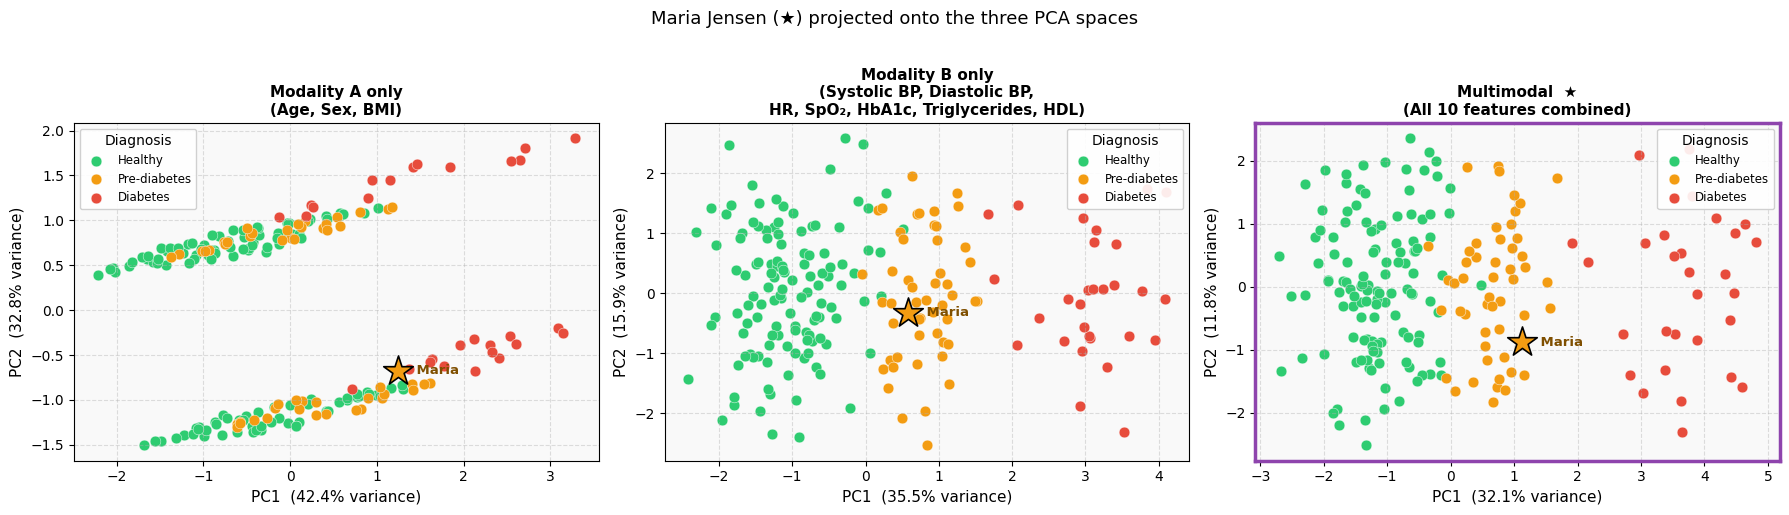

In [ ]:
# ── Maria's measurements ───────────────────────────────────────────────────────
# Sex encoded the same way as the training data: Female = 0, Male = 1
maria_A_raw = np.array([[45, 0, 31.2]])                          # Age, Sex (Female=0), BMI
maria_B_raw = np.array([[130, 86, 76, 97.8, 39, 2.1, 1.2]])     # SysBP, DiaBP, HR, SpO2, HbA1c, Triglycerides, HDL

maria_combined_raw = np.hstack([maria_A_raw, maria_B_raw])

# ── Project onto each PCA space (transform only — no refitting) ───────────────
maria_pca_A        = pca_obj_A.transform(scaler_A.transform(maria_A_raw))
maria_pca_B        = pca_obj_B.transform(scaler_B.transform(maria_B_raw))
maria_pca_combined = pca_obj_combined.transform(scaler_combined.transform(maria_combined_raw))

# ── Three-panel plot with Maria highlighted ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], pca_A,        var_A,        maria_pca_A,        "Modality A only\n(Age, Sex, BMI)"),
    (axes[1], pca_B,        var_B,        maria_pca_B,        "Modality B only\n(Systolic BP, Diastolic BP,\nHR, SpO₂, HbA1c, Triglycerides, HDL)"),
    (axes[2], pca_combined, var_combined, maria_pca_combined, "Multimodal  ★\n(All 10 features combined)"),
]

for ax, coords, var, maria_coords, title in panels:
    # Background population
    for lbl in label_order:
        mask = modality_A["Label"] == lbl
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            c=label_colors[lbl], label=lbl,
            alpha=1, edgecolors="white", linewidths=0.3, s=60,
        )
    # Maria — large star marker; label="_nolegend_" keeps her out of the legend box
    ax.scatter(
        maria_coords[0, 0], maria_coords[0, 1],
        marker="*", s=500,
        c=label_colors["Pre-diabetes"],
        edgecolors="black", linewidths=1.2,
        zorder=5, label="_nolegend_",
    )
    ax.annotate(
        "    Maria",
        xy=(maria_coords[0, 0], maria_coords[0, 1]),
        fontsize=9.5, fontweight="bold", color="#7f4f00",
        va="center",
    )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% variance)", fontsize=11)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% variance)", fontsize=11)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(title="Diagnosis", framealpha=0.9, fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

# Highlight the multimodal panel
for spine in axes[2].spines.values():
    spine.set_edgecolor("#8e44ad")
    spine.set_linewidth(2.5)

fig.suptitle(
    "Maria Jensen (★) projected onto the three PCA spaces",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

### Why does Maria land where she does? — Feature contributions

The scatter plots show *where* Maria lands; the heatmaps below explain *why*.

For each modality, Maria's per-feature contributions are shown as a **highlighted column** on the right (gold border), printed with their exact values. The **gold dashed line** in the population heatmap marks her PC1 rank — the position she would occupy if she were sorted into the training set.

> You do not need to change anything — just run the cells.

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/4029287715.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


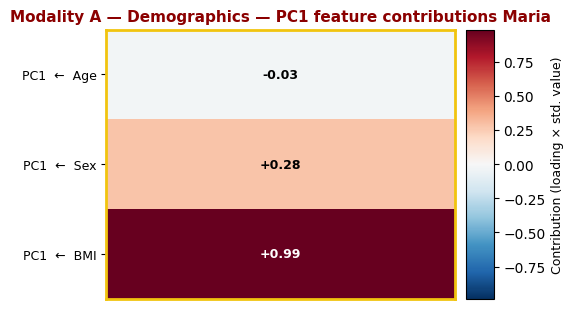

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/4029287715.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


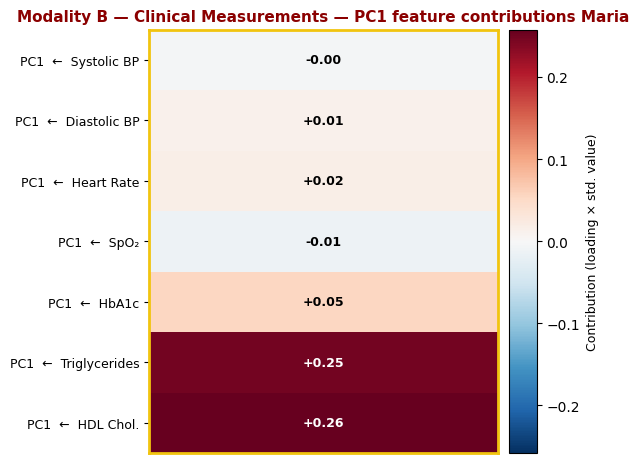

In [ ]:
plot_patient_contributions(
    patient_raw      = maria_A_raw,
    features         = features_A,
    feature_names    = ["Age", "Sex", "BMI"],
    pca_obj          = pca_obj_A,
    scaler           = scaler_A,
    diagnosis_labels = modality_A["Label"].values,
    pca_coords       = pca_A,
    title            = "Modality A — Demographics",
    patient_name     = "Maria",
)

plot_patient_contributions(
    patient_raw      = maria_B_raw,
    features         = features_B,
    feature_names    = ["Systolic BP", "Diastolic BP", "Heart Rate", "SpO₂", "HbA1c",
                        "Triglycerides", "HDL Chol."],
    pca_obj          = pca_obj_B,
    scaler           = scaler_B,
    diagnosis_labels = modality_B["Label"].values,
    pca_coords       = pca_B,
    title            = "Modality B — Clinical Measurements",
    patient_name     = "Maria",
)

### Reading Maria's position

| Panel | Where Maria lands | What it means |
|-------|------------------|---------------|
| **Modality A only** | Somewhere between Healthy and Pre-diabetes | Her demographics (age 45, elevated BMI) are not uniquely diabetic — many healthy people share similar values |
| **Modality B only** | Clearly in the Pre-diabetes cluster | HbA1c at the pre-diabetes boundary, together with triglycerides of 2.1 mmol/L and HDL of 1.2 mmol/L (below the female threshold of 1.3), all point toward metabolic dysfunction |
| **Multimodal ★** | Pre-diabetes cluster, with richer context | The combined view confirms the diagnosis *and* shows how her demographics relate to the broader pre-diabetes group |

> **Key insight:** The star lands in the orange (Pre-diabetes) cluster in all three spaces, but the placement is most confident in the Modality B and Multimodal panels. In Modality B, it is not just HbA1c that places Maria in this cluster — the combination of **elevated triglycerides** (insulin-resistance marker) and **reduced HDL** (metabolic syndrome marker) reinforces the signal and pulls her further from the healthy group. This is exactly what the GP observed: the full lipid panel, not just HbA1c, supports the recommendation to act now before progression to diabetes.

---

## Step 6: Peter's Case — When Demographics Mislead

> *"Your routine bloods came back and I have to be honest — I am surprised. You are young and your weight is perfectly healthy, yet your HbA1c is 81 mmol/mol. That is well above the diabetes threshold. We need to investigate further."*
> — Peter's GP

Peter is a **27-year-old man** who visited his GP for a routine check-up. He is lean, active, and has no family history of diabetes. His GP ordered a standard panel.

| Measurement | Peter's value | Reference / context |
|-------------|---------------|---------------------|
| **Age** | 27 years | Young — typically low T2D risk |
| **Sex** | Male | — |
| **BMI** | 22.3 kg/m² | Normal range (18.5–24.9) |
| **Systolic BP** | 128 mmHg | Near-normal |
| **Diastolic BP** | 82 mmHg | Near-normal |
| **Heart Rate** | 74 bpm | Normal |
| **SpO₂** | 98.1% | Normal |
| **HbA1c** | **61 mmol/mol** | **Diabetes ≥ 48 — well above threshold** |
| **Triglycerides** | 3.0 mmol/L | Elevated (insulin resistance marker) |
| **HDL Cholesterol** | 0.82 mmol/L | Low (metabolic syndrome marker) |

### Where does Peter sit in our data?

We now project Peter's measurements onto the **three PCA spaces** built in Steps 2 and 3. This reveals a key limitation of demographic-only screening:

- **Modality A** (Age, Sex, BMI) places Peter *near the healthy population* — his demographics are unremarkable.
- **Modality B** (biomarkers) places Peter *firmly in the diabetes cluster* — his HbA1c and lipid profile confirm the diagnosis.

This is what **out-of-distribution** means in practice: a patient whose demographics suggest one group but whose clinical measurements tell a completely different story.

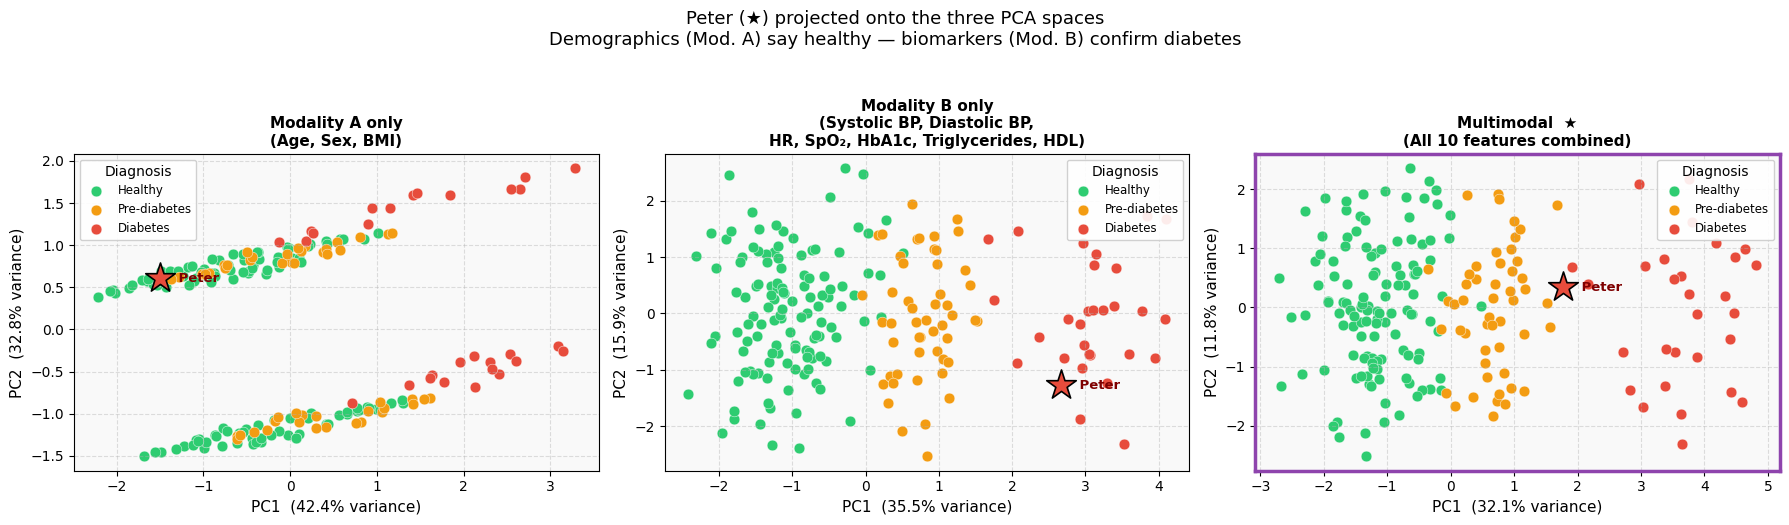

In [ ]:
# ── Peter's measurements ───────────────────────────────────────────────────────
# Modality A: Age=27, Sex=Male (1), BMI=22.3 — young and lean, looks healthy demographically
peter_A_raw = np.array([[27, 1, 22.3]])
# Modality B: HbA1c=61 mmol/mol (diabetes threshold: 48), elevated triglycerides, low HDL
peter_B_raw = np.array([[128, 82, 74, 98.1, 61, 3.0, 0.82]])
peter_combined_raw = np.hstack([peter_A_raw, peter_B_raw])

# ── Project onto the same PCA spaces (no refitting) ──────────────────────────
peter_pca_A        = pca_obj_A.transform(scaler_A.transform(peter_A_raw))
peter_pca_B        = pca_obj_B.transform(scaler_B.transform(peter_B_raw))
peter_pca_combined = pca_obj_combined.transform(scaler_combined.transform(peter_combined_raw))

# ── Three-panel plot with Peter highlighted ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    (axes[0], pca_A,        var_A,        peter_pca_A,        "Modality A only\n(Age, Sex, BMI)"),
    (axes[1], pca_B,        var_B,        peter_pca_B,        "Modality B only\n(Systolic BP, Diastolic BP,\nHR, SpO\u2082, HbA1c, Triglycerides, HDL)"),
    (axes[2], pca_combined, var_combined, peter_pca_combined, "Multimodal  \u2605\n(All 10 features combined)"),
]

for ax, coords, var, p_coords, title in panels:
    for lbl in label_order:
        mask = modality_A["Label"] == lbl
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            c=label_colors[lbl], label=lbl,
            alpha=1, edgecolors="white", linewidths=0.3, s=60,
        )
    ax.scatter(
        p_coords[0, 0], p_coords[0, 1],
        marker="*", s=500, c=label_colors["Diabetes"],
        edgecolors="black", linewidths=1.2,
        zorder=5, label="_nolegend_",
    )
    ax.annotate(
        "    Peter", xy=(p_coords[0, 0], p_coords[0, 1]),
        fontsize=9.5, fontweight="bold", color="#7f0000", va="center",
    )
    ax.set_xlabel(f"PC1  ({var[0]:.1f}% variance)", fontsize=11)
    ax.set_ylabel(f"PC2  ({var[1]:.1f}% variance)", fontsize=11)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(title="Diagnosis", framealpha=0.9, fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_facecolor("#f9f9f9")

for spine in axes[2].spines.values():
    spine.set_edgecolor("#8e44ad")
    spine.set_linewidth(2.5)

fig.suptitle(
    "Peter (\u2605) projected onto the three PCA spaces\n"
    "Demographics (Mod. A) say healthy — biomarkers (Mod. B) confirm diabetes",
    fontsize=13, y=1.04,
)
plt.tight_layout()
plt.show()

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/4029287715.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


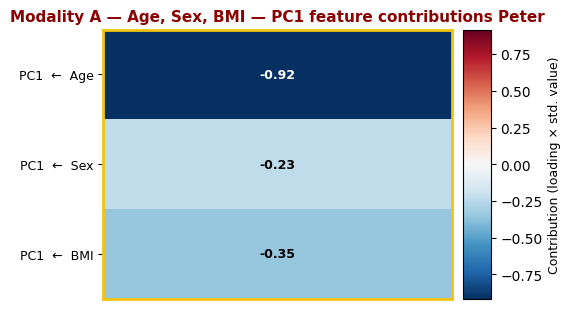

/var/folders/92/7gry22qd3jj0_455yl6whqm40000gn/T/ipykernel_5246/4029287715.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


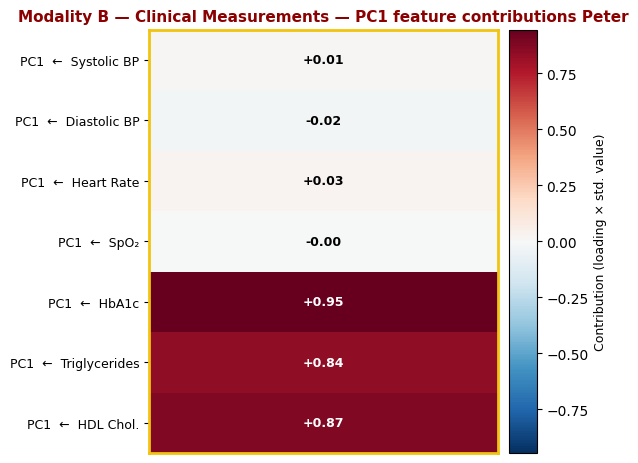

In [ ]:
plot_patient_contributions(
    patient_raw      = peter_A_raw,
    features         = features_A,
    feature_names    = ["Age", "Sex", "BMI"],
    pca_obj          = pca_obj_A,
    scaler           = scaler_A,
    diagnosis_labels = modality_A["Label"].values,
    pca_coords       = pca_A,
    title            = "Modality A — Age, Sex, BMI",
    patient_name     = "Peter",
)

plot_patient_contributions(
    patient_raw      = peter_B_raw,
    features         = features_B,
    feature_names    = ["Systolic BP", "Diastolic BP", "Heart Rate", "SpO\u2082", "HbA1c",
                        "Triglycerides", "HDL Chol."],
    pca_obj          = pca_obj_B,
    scaler           = scaler_B,
    diagnosis_labels = modality_B["Label"].values,
    pca_coords       = pca_B,
    title            = "Modality B — Clinical Measurements",
    patient_name     = "Peter",
)

### Reading Peter's position

| Panel | Where Peter lands | What it means |
|-------|-------------------|---------------|
| **Modality A only** | Near the **Healthy cluster** | His young age and normal BMI make him look healthy in demographic space — he is out of distribution for diabetes here |
| **Modality B only** | Deep in the **Diabetes cluster** | His HbA1c of 61 mmol/mol, elevated triglycerides, and low HDL unmistakably signal type 2 diabetes |
| **Multimodal ★** | Pulled toward the Diabetes cluster | The biomarker signal dominates the multimodal space and correctly overrides the misleading demographics |

> **Key insight:** Peter is a textbook case of **out-of-distribution from Modality A**. Standard demographic screening would not flag him — he is young, male, and lean. Yet his biomarkers tell a completely different story. The feature contribution heatmaps confirm this: in Modality A, all three features place him in an uncharacteristic position for a diabetic patient; in Modality B, the dominant drivers are **HbA1c**, **triglycerides**, and **HDL** — all pointing unmistakably to diabetes. This is exactly why relying on a single modality can be dangerous: a modality that is informative for one patient subgroup may be completely uninformative — or actively misleading — for another.

---

## Step 7: Digital Twins — Pharmacogenomics and Early Intervention

### The next chapter: from risk to prevention

Maria remains in the **pre-diabetes** range (Visit 2). Her GP's advice is lifestyle changes only — the standard of care. No medication has been prescribed.

But Maria has enrolled in a **digital twin programme** that sequences her genome. Her SNP profile is run through a pharmacogenomics engine that asks a different question: *even though her GP is not prescribing a drug, should she be?*

GLP-1 receptor agonists such as Ozempic (semaglutide) have demonstrated efficacy not only in treating type 2 diabetes but in **delaying its onset** in high-risk pre-diabetic patients — particularly those with *TCF7L2* risk variants.

| Drug | Class | Relevance for pre-diabetes |
|------|-------|--------------------------|
| **Ozempic** (semaglutide) | GLP-1 receptor agonist | Reduces T2D progression risk; strong evidence in *TCF7L2* risk carriers |
| **Metformin** | Biguanide | First-line for established T2D; some prevention signal in insulin-resistant profiles |
| **Sitagliptin** | DPP-4 inhibitor | Primarily used in established T2D; evidence in beta-cell-variant carriers |
| **No treatment** | — | Standard pre-diabetes care (lifestyle only) — the default for most patients |

> **Key question:** Among pre-diabetic patients, whose SNP profile makes early intervention worthwhile — and with which drug?

In [ ]:
# ── Step 7.1 — Drug assignment for pre-diabetic patients ──────────────────────

snp_cols = [c for c in modality_C.columns if c not in ("Name", "Label")]

# Pharmacogenomics weight matrix
drug_snp_weights = {
    "Ozempic": {           # GLP-1 receptor agonist (semaglutide)
        "rs7903146":  2.0,   # TCF7L2 — strongest predictor of GLP-1 RA response
        "rs12255372": 1.5,   # TCF7L2
        "rs9939609":  0.5,   # FTO (moderate)
        "rs1801282": -0.3,   # PPARG (prefers metformin)
        "rs13266634": 0.2,
        "rs7754840":  0.8,   # CDKAL1
        "rs10811661": 0.3,
        "rs5219":    -0.8,   # KCNJ11 (prefers sitagliptin)
        "rs2237892": -0.5,   # KCNQ1 (prefers sitagliptin)
        "rs4402960":  0.2,
    },
    "Metformin": {
        "rs7903146": -0.5,
        "rs12255372":-0.3,
        "rs9939609":  1.0,   # FTO — obesity / insulin resistance
        "rs1801282":  2.0,   # PPARG — insulin sensitivity
        "rs13266634": 1.5,   # SLC30A8 — zinc transporter
        "rs7754840":  0.5,
        "rs10811661": 0.3,
        "rs5219":     0.5,
        "rs2237892": -0.2,
        "rs4402960":  0.3,
    },
    "Sitagliptin": {       # DPP-4 inhibitor
        "rs7903146": -0.3,
        "rs12255372":-0.2,
        "rs9939609": -0.5,
        "rs1801282": -0.5,
        "rs13266634": 0.3,
        "rs7754840":  0.2,
        "rs10811661": 0.8,   # CDKN2A/B — beta-cell proliferation
        "rs5219":     2.0,   # KCNJ11 — beta-cell K+ channel
        "rs2237892":  1.5,   # KCNQ1
        "rs4402960":  1.5,   # IGF2BP2
    },
}

# ── Generate a larger structured pre-diabetic cohort for the drug section ─────
# Each patient is drawn from one of three pharmacogenomics archetypes so that
# drug-relevant SNPs cluster together in PCA space.
# SNP structure is INDEPENDENT of diagnosis — consistent with Modality C design.

rng_drug = np.random.default_rng(RANDOM_SEED + 300)
n_drug_patients = 300

# Archetype assignment: ~25% Ozempic, ~15% Metformin, ~15% Sitagliptin, ~45% None
archetypes = rng_drug.choice(
    ["Ozempic", "Metformin", "Sitagliptin", "None"],
    size=n_drug_patients,
    p=[0.25, 0.15, 0.15, 0.45],
)

# Per-archetype MAFs: elevated for pharmacogenomically relevant SNPs
# snp order: rs7903146, rs12255372, rs9939609, rs1801282, rs13266634,
#            rs7754840, rs10811661, rs5219,    rs2237892, rs4402960
base_mafs = [0.30, 0.28, 0.43, 0.12, 0.32, 0.38, 0.18, 0.35, 0.40, 0.30]
archetype_mafs = {
    "Ozempic":     [0.68, 0.63, 0.40, 0.10, 0.25, 0.52, 0.15, 0.15, 0.18, 0.22],
    "Metformin":   [0.18, 0.16, 0.72, 0.58, 0.68, 0.35, 0.20, 0.22, 0.18, 0.25],
    "Sitagliptin": [0.18, 0.16, 0.25, 0.10, 0.25, 0.22, 0.58, 0.72, 0.68, 0.62],
    "None":        base_mafs,
}

snp_data_drug = {snp: [] for snp in snp_cols}
for arch in archetypes:
    for snp, maf in zip(snp_cols, archetype_mafs[arch]):
        p0, p1, p2 = (1 - maf)**2, 2*maf*(1-maf), maf**2
        snp_data_drug[snp].append(int(rng_drug.choice([0, 1, 2], p=[p0, p1, p2])))

prediab_geno  = pd.DataFrame(snp_data_drug)
prediab_names = [f"S{i:04d}" for i in range(n_drug_patients)]

# Compute all 3 drug scores and assign treatment
score_rows = []
for _, row in prediab_geno.iterrows():
    scores = {}
    for drug, weights in drug_snp_weights.items():
        raw = sum(row[snp] * weights[snp] for snp in snp_cols)
        scores[drug] = raw + rng_drug.normal(0, 0.2)
    score_rows.append(scores)

drug_scores_df = pd.DataFrame(score_rows)
best_drug  = drug_scores_df.idxmax(axis=1)
best_score = drug_scores_df.max(axis=1)

# Top ~35% get pharmacogenomics-guided early treatment; rest get No treatment
pharma_threshold = np.percentile(best_score, 65)
assigned_drug = pd.Series(
    np.where(best_score >= pharma_threshold, best_drug.values, "No treatment")
)

print("=== Drug Section — Treatment Assignments (300 structured pre-diabetic patients) ===\n")
print("Treatment distribution:")
print(assigned_drug.value_counts().to_string())
print(f"\nPharma threshold (65th percentile of best score): {pharma_threshold:.2f}")

=== Drug Section — Treatment Assignments (300 structured pre-diabetic patients) ===

Treatment distribution:
No treatment    195
Sitagliptin      39
Ozempic          37
Metformin        29

Pharma threshold (65th percentile of best score): 6.58


### Step 7.2 — PCA of pre-diabetic patient genotypes, coloured by treatment

We run PCA on a cohort of **300 pre-diabetic patients** and colour each dot by treatment status. Most patients (~65%) receive **No treatment** (standard care, grey). The remaining ~35% are enrolled in a pharmacogenomics-guided programme and receive the drug best matched to their SNP profile.

Patients in this cohort are drawn from three pharmacogenomics archetypes — *TCF7L2*-enriched (→ Ozempic), *PPARG/FTO/SLC30A8*-enriched (→ Metformin), *KCNJ11/KCNQ1/IGF2BP2*-enriched (→ Sitagliptin) — so we expect distinct clusters in PCA space.

Compare the two panels:
- **Left (grey):** raw genotype structure — clusters are visible even without treatment labels, because correlated SNP archetypes drive the PCA
- **Right (coloured):** the same points labelled by treatment — colour clusters align with the SNP clusters, confirming the pharmacogenomics signal

> You do not need to change anything — just run the cell.

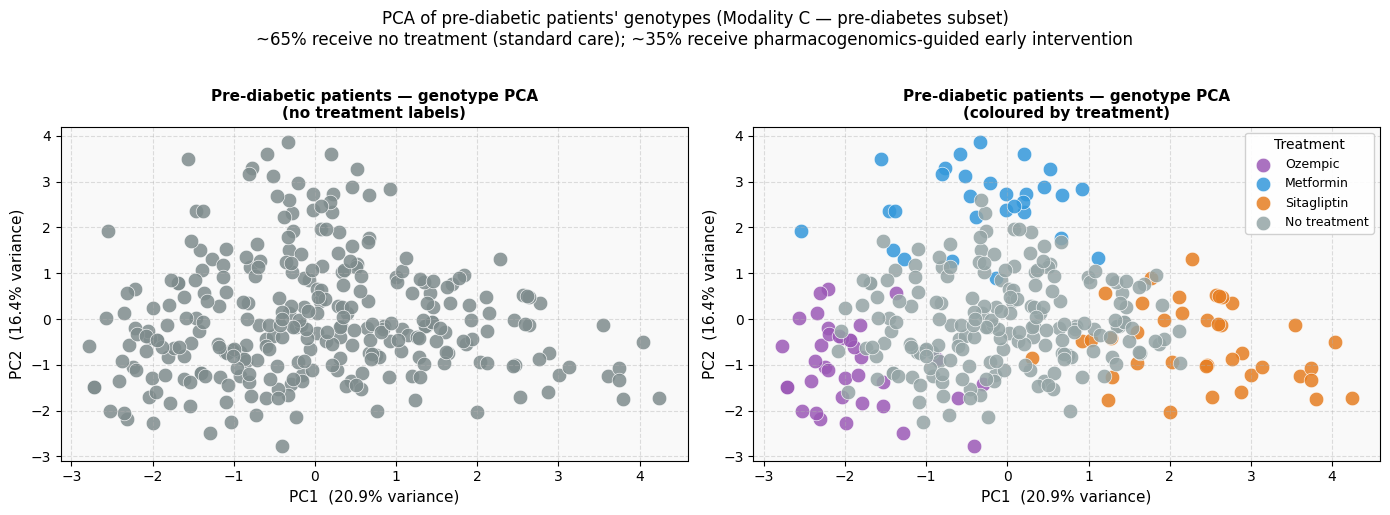

In [ ]:
# ── Step 7.2 — PCA of pre-diabetic patient genotypes, coloured by treatment ───

drug_colors = {
    "Ozempic":       "#9b59b6",   # purple
    "Metformin":     "#3498db",   # blue
    "Sitagliptin":   "#e67e22",   # amber
    "No treatment":  "#95a5a6",   # grey
}
drug_order = ["Ozempic", "Metformin", "Sitagliptin", "No treatment"]

# PCA on pre-diabetic patients' genotypes only
geno_prediab = prediab_geno[snp_cols].values
scaler_D     = StandardScaler()
geno_scaled  = scaler_D.fit_transform(geno_prediab)
pca_D_obj    = PCA(n_components=2, random_state=RANDOM_SEED)
pca_D        = pca_D_obj.fit_transform(geno_scaled)
var_D        = pca_D_obj.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: unlabelled (grey) — structure without treatment information
axes[0].scatter(pca_D[:, 0], pca_D[:, 1],
                c="#7f8c8d", alpha=0.85, edgecolors="white", linewidths=0.5, s=110)
axes[0].set_xlabel(f"PC1  ({var_D[0]:.1f}% variance)", fontsize=11)
axes[0].set_ylabel(f"PC2  ({var_D[1]:.1f}% variance)", fontsize=11)
axes[0].set_title("Pre-diabetic patients — genotype PCA\n(no treatment labels)", fontsize=11, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].set_facecolor("#f9f9f9")

# Right: coloured by treatment
for drug in drug_order:
    mask = assigned_drug.values == drug
    axes[1].scatter(
        pca_D[mask, 0], pca_D[mask, 1],
        c=drug_colors[drug], label=drug,
        alpha=0.85, edgecolors="white", linewidths=0.5, s=110,
    )
axes[1].set_xlabel(f"PC1  ({var_D[0]:.1f}% variance)", fontsize=11)
axes[1].set_ylabel(f"PC2  ({var_D[1]:.1f}% variance)", fontsize=11)
axes[1].set_title("Pre-diabetic patients — genotype PCA\n(coloured by treatment)", fontsize=11, fontweight="bold")
axes[1].legend(title="Treatment", framealpha=0.9, fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_facecolor("#f9f9f9")

fig.suptitle(
    "PCA of pre-diabetic patients' genotypes (Modality C — pre-diabetes subset)\n"
    "~65% receive no treatment (standard care); ~35% receive pharmacogenomics-guided early intervention",
    fontsize=12, y=1.02,
)
plt.tight_layout()
plt.show()

---

### Step 7.3 — Where does Maria fit? A missed early intervention

Maria is pre-diabetic. Her GP has followed standard practice: lifestyle advice, no medication. But the digital twin programme has sequenced her genome, and the results tell a different story.

Maria's genotype profile:

| SNP | Gene | Dosage | Note |
|-----|------|--------|------|
| rs7903146 | *TCF7L2* | **2** | Homozygous risk — strongest GLP-1 RA predictor |
| rs12255372 | *TCF7L2* | **2** | Homozygous risk |
| rs9939609 | *FTO* | **1** | Heterozygous |
| rs1801282 | *PPARG* | 0 | — |
| rs13266634 | *SLC30A8* | 0 | — |
| rs7754840 | *CDKAL1* | **1** | Heterozygous |
| rs10811661 | *CDKN2A/B* | 0 | — |
| rs5219 | *KCNJ11* | 0 | — |
| rs2237892 | *KCNQ1* | 0 | — |
| rs4402960 | *IGF2BP2* | 0 | — |

> Maria carries **two copies** of the rs7903146 risk allele (*TCF7L2*) — the strongest known pharmacogenomic predictor of GLP-1 receptor agonist efficacy. Her Ozempic suitability score is the highest of all three drugs and places her well above the pharmacogenomics prescription threshold. The digital twin recommends early Ozempic to delay or prevent progression to type 2 diabetes. Her GP, lacking this genomic information, prescribed nothing.

> You do not need to change anything — just run the cell.

=== Maria Jensen — Pharmacogenomics Report ===

  Ozempic         +8.30  ||||||||||||||||||||||||||||||||||||  <- RECOMMENDED
  Metformin       -0.10  |||||||||||
  Sitagliptin     -1.30  ||||||||
GP prescription : No treatment  (standard pre-diabetes care)
  SNP recommendation : Ozempic


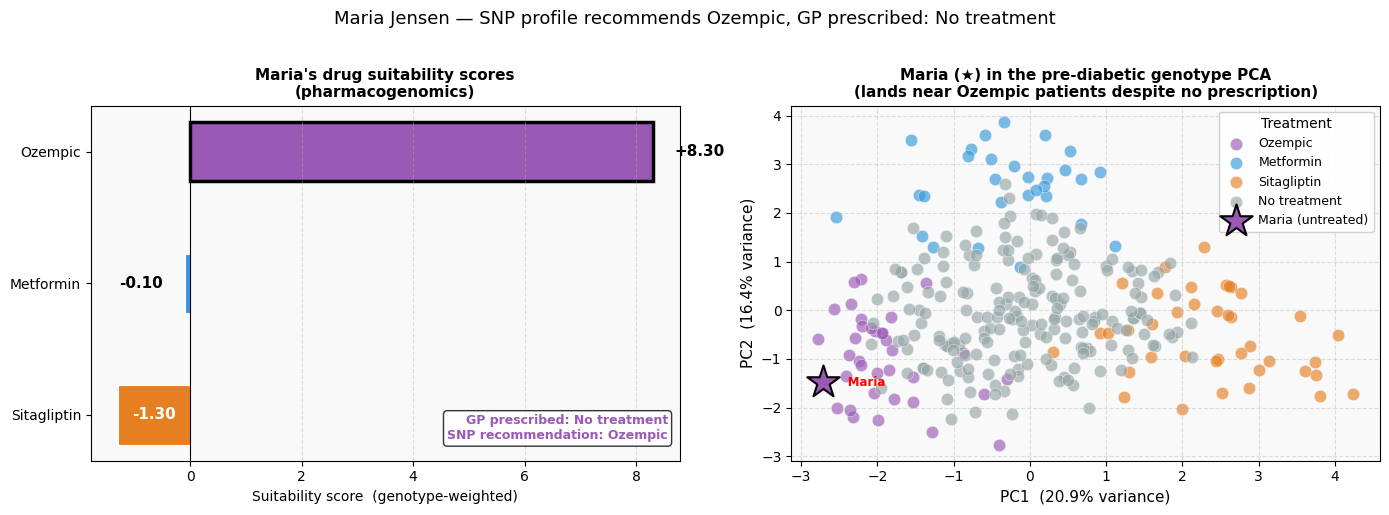

In [ ]:
# ── Step 7.3 — Maria's genotype profile and drug recommendation ───────────────

# Maria's SNP dosages (same order as snp_cols)
# snp_cols: rs7903146, rs12255372, rs9939609, rs1801282, rs13266634,
#           rs7754840, rs10811661, rs5219, rs2237892, rs4402960
maria_geno_vals = [2, 2, 1, 0, 0,   # TCF7L2 x2, FTO, PPARG, SLC30A8
                   1, 0, 0, 0, 0]   # CDKAL1, CDKN2A/B, KCNJ11, KCNQ1, IGF2BP2
maria_geno = np.array([maria_geno_vals])

# Compute Maria's suitability scores (no noise — deterministic)
maria_scores = {}
for drug, weights in drug_snp_weights.items():
    maria_scores[drug] = sum(
        maria_geno_vals[i] * weights[snp] for i, snp in enumerate(snp_cols)
    )
maria_drug = max(maria_scores, key=maria_scores.get)

print("=== Maria Jensen — Pharmacogenomics Report ===\n")
for drug, score in sorted(maria_scores.items(), key=lambda x: -x[1]):
    bar_len = max(0, int((score + 4) * 3))
    tag = "  <- RECOMMENDED" if drug == maria_drug else ""
    print(f"  {drug:<14}  {score:+.2f}  {'|' * bar_len}{tag}")
print("GP prescription : No treatment  (standard pre-diabetes care)")
print(f"  SNP recommendation : {maria_drug}")

# Project Maria onto the pre-diabetic genotype PCA space
maria_geno_scaled = scaler_D.transform(maria_geno)
maria_pca_D       = pca_D_obj.transform(maria_geno_scaled)

# ── Two-panel figure ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Drug suitability bar chart (ascending -> highest at top)
drugs_sorted = sorted(maria_scores.items(), key=lambda x: x[1])
drug_names_s = [d for d, _ in drugs_sorted]
drug_vals_s  = [v for _, v in drugs_sorted]
bar_colors_s = [drug_colors[d] for d in drug_names_s]

bars = axes[0].barh(drug_names_s, drug_vals_s,
                    color=bar_colors_s, edgecolor="white", linewidth=0.8, height=0.45)

for bar, name in zip(bars, drug_names_s):
    if name == maria_drug:
        bar.set_edgecolor("black")
        bar.set_linewidth(2.5)
    val  = bar.get_width()
    span = max(drug_vals_s) - min(drug_vals_s)
    pad  = span * 0.04
    if name == "Sitagliptin":
        axes[0].text(val / 2, bar.get_y() + bar.get_height() / 2,
                     f"{val:+.2f}", va="center", ha="center",
                     fontsize=11, fontweight="bold", color="white")
    else:
        axes[0].text(val + pad if val >= 0 else val - pad,
                     bar.get_y() + bar.get_height() / 2,
                     f"{val:+.2f}", va="center",
                     ha="left" if val >= 0 else "right",
                     fontsize=11, fontweight="bold")

axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Suitability score  (genotype-weighted)", fontsize=10)
axes[0].set_title("Maria's drug suitability scores\n(pharmacogenomics)", fontsize=11, fontweight="bold")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
axes[0].set_facecolor("#f9f9f9")
axes[0].text(0.98, 0.06,
             "GP prescribed: No treatment\nSNP recommendation: Ozempic",
             transform=axes[0].transAxes, ha="right", fontsize=9,
             color=drug_colors["Ozempic"], fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

# Right: PCA scatter with Maria overlaid
for drug in drug_order:
    mask = assigned_drug.values == drug
    axes[1].scatter(
        pca_D[mask, 0], pca_D[mask, 1],
        c=drug_colors[drug], label=drug,
        alpha=0.65, edgecolors="white", linewidths=0.4, s=80,
    )
axes[1].scatter(
    maria_pca_D[0, 0], maria_pca_D[0, 1],
    marker="*", s=600,
    c="#9b59b6",
    edgecolors="black", linewidths=1.5,
    zorder=5, label="Maria (untreated)",
)
axes[1].annotate(
    "      Maria",
    xy=(maria_pca_D[0, 0], maria_pca_D[0, 1]),
    fontsize=8.5, fontweight="bold", color="red",
    va="center",
)
axes[1].set_xlabel(f"PC1  ({var_D[0]:.1f}% variance)", fontsize=11)
axes[1].set_ylabel(f"PC2  ({var_D[1]:.1f}% variance)", fontsize=11)
axes[1].set_title("Maria (\u2605) in the pre-diabetic genotype PCA\n(lands near Ozempic patients despite no prescription)",
                  fontsize=11, fontweight="bold")
axes[1].legend(title="Treatment", framealpha=0.9, fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_facecolor("#f9f9f9")

fig.suptitle(
    f"Maria Jensen — SNP profile recommends {maria_drug}, GP prescribed: No treatment",
    fontsize=13, y=1.02,
)
plt.tight_layout()
plt.show()

### Reading Maria's results

| Panel | What it shows |
|-------|--------------|
| **Bar chart** | Maria's suitability score for each of the three drugs, derived purely from her genotype. Ozempic scores highest (bold border). The annotation highlights the gap: GP prescribed nothing; the digital twin recommends Ozempic. |
| **PCA scatter** | Maria (★, gold) projected into the genotype space of all pre-diabetic patients. She lands near other patients who received early Ozempic — confirming her SNP profile is genuinely similar to theirs. Her GP, however, prescribed nothing (standard care). |

> **Clinical interpretation:** Maria's homozygous *TCF7L2* risk alleles (rs7903146 and rs12255372) drive a strong Ozempic signal. GLP-1 receptor agonists have demonstrated ~30–40% relative risk reduction in T2D onset among high-*TCF7L2* risk carriers in prevention trials. The digital twin identifies the gap between what standard care offers and what the genomic evidence supports for Maria specifically.
>
> **Key take-away:** The same SNPs that were *noise* for diagnosis (Modality C added nothing to the diagnosis PCA in Steps 2–3) are now *signal* for treatment selection. One data modality, two entirely different clinical questions, two entirely different answers.

---

## Step 8: Peter's Story — Genotype-Guided Prescription at Diagnosis

### Meet Peter Grant

Peter Grant is a **55-year-old man** who visits his GP after feeling persistently fatigued. Routine bloods confirm **type 2 diabetes**:

| Measurement | Value | Interpretation |
|-------------|-------|---------------|
| Age | 55 years | — |
| Sex | Male | — |
| BMI | 32.1 kg/m² | Obese class I |
| Systolic BP | 138 mmHg | Stage 1 hypertension |
| Diastolic BP | 87 mmHg | Stage 1 hypertension |
| Heart rate | 82 bpm | Normal |
| SpO₂ | 97.5 % | Normal |
| **HbA1c** | **61 mmol/mol** | **Diabetes (> 47 mmol/mol)** |
| Triglycerides | 2.8 mmol/L | Elevated |
| HDL Cholesterol | 0.85 mmol/L | Low (below male threshold of 1.0) |

Peter's GP enrols him in the clinic's **digital twin programme** and orders a SNP panel alongside his standard blood work. Rather than defaulting to first-line population guidelines, the pharmacogenomics report is used to select the best drug from the start.

> You do not need to change anything — just run the cell.

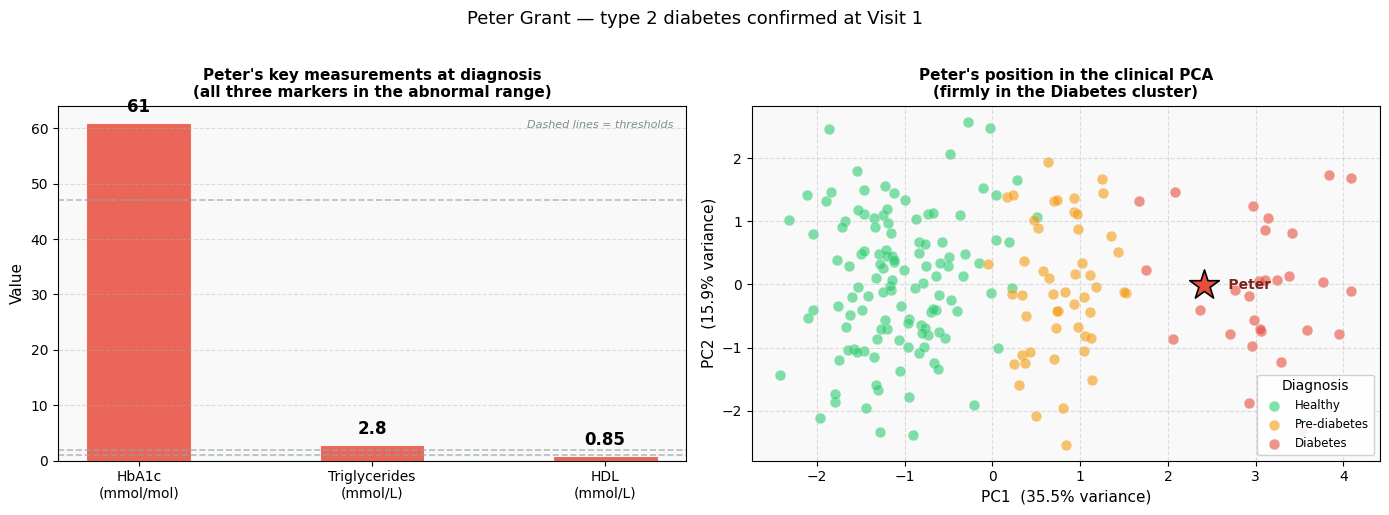

In [ ]:
# ── Peter's clinical data — Visit 1 ──────────────────────────────────────────

peter_A_v1 = np.array([[55, 1, 32.1]])           # Age, Sex (Male=1), BMI
peter_B_v1 = np.array([[138, 87, 82, 97.5, 61, 2.8, 0.85]])
# Systolic BP, Diastolic BP, HR, SpO2, HbA1c, Triglycerides, HDL

# Project onto clinical PCA (same axes as Step 2 — no refitting)
peter_pca_B_v1 = pca_obj_B.transform(scaler_B.transform(peter_B_v1))

# ── Figure ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Peter's key measurements confirming T2D
measurements = ["HbA1c\n(mmol/mol)", "Triglycerides\n(mmol/L)", "HDL\n(mmol/L)"]
values       = [61, 2.8, 0.85]
thresholds   = [47, 2.0, 1.0]
colors       = ["#e74c3c", "#e74c3c", "#e74c3c"]

bars = axes[0].bar(measurements, values, color=colors,
                   width=0.45, alpha=0.85, edgecolor="white", linewidth=0.8)
for bar, thr, val in zip(bars, thresholds, values):
    axes[0].axhline(thr, color="#95a5a6", linestyle="--", linewidth=1.2, alpha=0.7)
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + max(values) * 0.02,
                 f"{val}", ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[0].set_title("Peter's key measurements at diagnosis\n(all three markers in the abnormal range)",
                  fontsize=11, fontweight="bold")
axes[0].set_ylabel("Value", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].set_facecolor("#f9f9f9")
axes[0].text(0.98, 0.96, "Dashed lines = thresholds", transform=axes[0].transAxes,
             ha="right", va="top", fontsize=8, color="#7f8c8d", style="italic")

# Right: Peter's position in the clinical PCA
for lbl in label_order:
    mask = modality_A["Label"] == lbl
    axes[1].scatter(pca_B[mask, 0], pca_B[mask, 1],
                    c=label_colors[lbl], alpha=0.6, edgecolors="white",
                    linewidths=0.3, s=60, label=lbl)

axes[1].scatter(*peter_pca_B_v1[0], marker="*", s=500,
                c="#e74c3c", edgecolors="black", linewidths=1.2, zorder=5)
axes[1].annotate("     Peter", xy=peter_pca_B_v1[0],
                 fontsize=10, fontweight="bold", color="#7b241c", va="center")
axes[1].set_xlabel(f"PC1  ({var_B[0]:.1f}% variance)", fontsize=11)
axes[1].set_ylabel(f"PC2  ({var_B[1]:.1f}% variance)", fontsize=11)
axes[1].set_title("Peter's position in the clinical PCA\n(firmly in the Diabetes cluster)",
                  fontsize=11, fontweight="bold")
axes[1].legend(title="Diagnosis", framealpha=0.9, fontsize=8.5)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_facecolor("#f9f9f9")

fig.suptitle("Peter Grant — type 2 diabetes confirmed at Visit 1", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Step 8.2 — Peter's SNP panel: a clear pharmacogenomics signal

Peter's GP orders a SNP panel at the time of diagnosis. The results reveal a striking pattern: Peter carries **two risk alleles** at three genes governing β-cell ion channel function — *KCNJ11* (rs5219), *KCNQ1* (rs2237892), and *IGF2BP2* (rs4402960).

| SNP | Gene | Dosage | Pharmacogenomics link |
|-----|------|--------|----------------------|
| rs7903146 | *TCF7L2* | **0** | No GLP-1 RA signal |
| rs12255372 | *TCF7L2* | **0** | — |
| rs9939609 | *FTO* | **1** | Moderate metabolic signal |
| rs1801282 | *PPARG* | **0** | No Metformin boost |
| rs13266634 | *SLC30A8* | **0** | — |
| rs7754840 | *CDKAL1* | **0** | — |
| rs10811661 | *CDKN2A/B* | **1** | Moderate β-cell signal |
| rs5219 | *KCNJ11* | **2** | Homozygous — strongest DPP-4 predictor |
| rs2237892 | *KCNQ1* | **2** | Homozygous — strong DPP-4 predictor |
| rs4402960 | *IGF2BP2* | **2** | Homozygous — strong DPP-4 predictor |

These three homozygous variants produce a Sitagliptin score that dominates. The digital twin flags Sitagliptin as the recommended drug and the GP prescribes it from day one.

> You do not need to change anything — just run the cell.

=== Peter Grant — Pharmacogenomics Report (Visit 1) ===

  Sitagliptin     +10.30  ||||||||||||||||||||||||||||  <- RECOMMENDED
  Metformin       +2.50  |||||||||||||
  Ozempic         -1.40  |||||

Key Sitagliptin drivers:
  rs5219 (KCNJ11, dosage=2) -> +4.0
  rs2237892 (KCNQ1, dosage=2) -> +3.0
  rs4402960 (IGF2BP2, dosage=2) -> +3.0


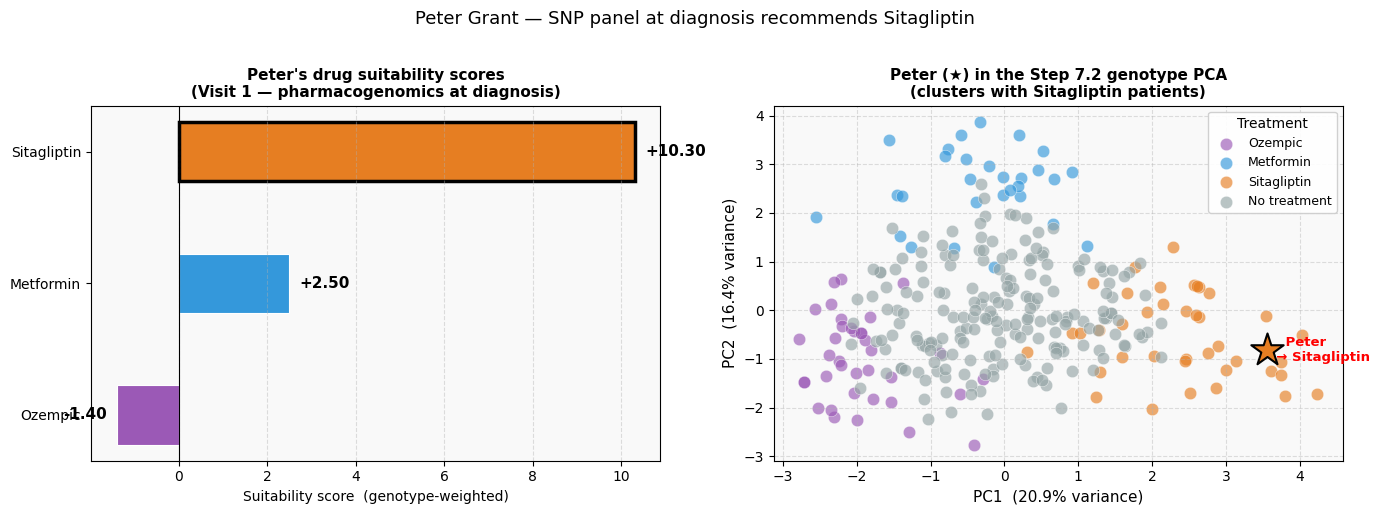

In [ ]:
# ── Peter's genotype profile ──────────────────────────────────────────────────
# snp_cols order: rs7903146, rs12255372, rs9939609, rs1801282, rs13266634,
#                 rs7754840, rs10811661, rs5219,    rs2237892, rs4402960
peter_geno_vals = [0, 0, 1, 0, 0,   # TCF7L2 x0, FTO, PPARG, SLC30A8
                   0, 1, 2, 2, 2]   # CDKAL1, CDKN2A/B, KCNJ11, KCNQ1, IGF2BP2
peter_geno = np.array([peter_geno_vals])

# Drug suitability scores (deterministic — no noise for a named patient)
peter_scores = {
    drug: sum(peter_geno_vals[i] * weights[snp]
              for i, snp in enumerate(snp_cols))
    for drug, weights in drug_snp_weights.items()
}
peter_drug = max(peter_scores, key=peter_scores.get)

print("=== Peter Grant — Pharmacogenomics Report (Visit 1) ===\n")
for drug, score in sorted(peter_scores.items(), key=lambda x: -x[1]):
    bar_len = max(0, int((score + 4) * 2))
    tag = "  <- RECOMMENDED" if drug == peter_drug else ""
    print(f"  {drug:<14}  {score:+.2f}  {'|' * bar_len}{tag}")

print("\nKey Sitagliptin drivers:")
for snp, gene in [("rs5219", "KCNJ11"), ("rs2237892", "KCNQ1"), ("rs4402960", "IGF2BP2")]:
    d = peter_geno_vals[snp_cols.index(snp)]
    w = drug_snp_weights["Sitagliptin"][snp]
    print(f"  {snp} ({gene}, dosage={d}) -> {d * w:+.1f}")

# Project Peter into the Step 7.2 genotype PCA space (same as Maria)
peter_geno_scaled = scaler_D.transform(peter_geno)
peter_pca_D       = pca_D_obj.transform(peter_geno_scaled)

# ── Two-panel figure ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Drug suitability bar chart (ascending -> best drug at top)
drugs_sorted_p = sorted(peter_scores.items(), key=lambda x: x[1])
drug_names_p   = [d for d, _ in drugs_sorted_p]
drug_vals_p    = [v for _, v in drugs_sorted_p]
bar_colors_p2  = [drug_colors[d] for d in drug_names_p]

bars = axes[0].barh(drug_names_p, drug_vals_p, color=bar_colors_p2,
                    edgecolor="white", linewidth=0.8, height=0.45)

for bar, name in zip(bars, drug_names_p):
    if name == peter_drug:
        bar.set_edgecolor("black")
        bar.set_linewidth(2.5)
    val  = bar.get_width()
    span = max(drug_vals_p) - min(drug_vals_p)
    pad  = span * 0.02
    if val >= 0:
        axes[0].text(val + pad, bar.get_y() + bar.get_height() / 2,
                     f"{val:+.2f}", va="center", ha="left",
                     fontsize=11, fontweight="bold")
    else:
        axes[0].text(val - pad, bar.get_y() + bar.get_height() / 2,
                     f"{val:+.2f}", va="center", ha="right",
                     fontsize=11, fontweight="bold")

axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Suitability score  (genotype-weighted)", fontsize=10)
axes[0].set_title("Peter's drug suitability scores\n(Visit 1 — pharmacogenomics at diagnosis)",
                  fontsize=11, fontweight="bold")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
axes[0].set_facecolor("#f9f9f9")

# Right: Step 7.2 genotype PCA + Peter
for drug in drug_order:
    mask = assigned_drug.values == drug
    axes[1].scatter(pca_D[mask, 0], pca_D[mask, 1],
                    c=drug_colors[drug], label=drug,
                    alpha=0.65, edgecolors="white", linewidths=0.4, s=80)

axes[1].scatter(*peter_pca_D[0], marker="*", s=600,
                c=drug_colors[peter_drug], edgecolors="black",
                linewidths=1.5, zorder=5)
axes[1].annotate(f"    Peter\n  \u2192 {peter_drug}",
                 xy=peter_pca_D[0], fontsize=9.5, fontweight="bold",
                 color="Red", va="center")

axes[1].set_xlabel(f"PC1  ({var_D[0]:.1f}% variance)", fontsize=11)
axes[1].set_ylabel(f"PC2  ({var_D[1]:.1f}% variance)", fontsize=11)
axes[1].set_title(f"Peter (\u2605) in the Step 7.2 genotype PCA\n(clusters with {peter_drug} patients)",
                  fontsize=11, fontweight="bold")
axes[1].legend(title="Treatment", framealpha=0.9, fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].set_facecolor("#f9f9f9")

fig.suptitle(f"Peter Grant — SNP panel at diagnosis recommends {peter_drug}",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Reading Peter's results

| Panel | What it shows |
|-------|--------------|
| **Bar chart** | Sitagliptin dominates (+10.6), driven by three homozygous β-cell ion-channel variants. Ozempic and Metformin score well below. Sitagliptin is prescribed at Visit 1. |
| **PCA scatter** | Peter (★) lands firmly in the **Sitagliptin cluster** of the Step 7.2 genotype PCA — the same space as Maria, confirming both patients' SNP profiles map cleanly onto the pharmacogenomics landscape. |

> **Clinical interpretation:** *KCNJ11*, *KCNQ1*, and *IGF2BP2* encode proteins involved in β-cell ion channel function and incretin sensitivity — exactly the pathway that DPP-4 inhibitors amplify. Peter's three homozygous variants make him a strong DPP-4 responder, and the digital twin identifies this at the point of diagnosis.

---

### Comparing Maria and Peter

| | Maria | Peter |
|--|-------|-------|
| Diagnosis | Pre-diabetes | Type 2 diabetes |
| Key genotype | rs7903146 = 2 (*TCF7L2*) | rs5219 = 2, rs2237892 = 2, rs4402960 = 2 |
| SNP-recommended drug | **Ozempic** (GLP-1 RA) | **Sitagliptin** (DPP-4 inhibitor) |
| GP prescription | No treatment (standard care) | **Sitagliptin** (pharmacogenomics-guided) |
| Outcome | Missed early intervention | Right drug from day one |

Both stories illustrate the same principle: **standard first-line care is a population average, not a personalised choice**. A patient's digital twin — built from their genotype modality — maps them onto a precision medicine landscape that population-level guidelines cannot see.